# KAN-ODE on SSAQS: early warning of high-anxiety / high-stress days
Run the cells **top to bottom**. Every result is saved to Google Drive, so a restarted session loses nothing.

| Cells | What happens |
|---|---|
| 1-2 | Connect Drive, set the folders |
| 3-13 | Write the project files (one cell per file) |
| 14 | Quick self-test of the model |
| 15-16 | Prepare the data and look at the exploration figures |
| 17 | Smoke test (3 epochs, 1 fold) |
| 18 | **Full training** (5 user-level folds, early stopping, best model saved, auto-resume) |
| 19-20 | Evaluation: baselines, lead time, conformal coverage per group, figures |
| 21-22 | Ablations (GRU, pooling, MLP) and comparison figure |

**After a restart:** run cells 1, 2 (and 14 is optional), then simply run cell 18 again. Finished folds are skipped, an interrupted fold resumes from its last saved epoch.

In [ ]:
# CELL 1 - connect Google Drive and set the folders (edit the 3 paths if yours differ)
import os, sys
try:
    from google.colab import drive
    drive.mount('/content/drive')
    IN_COLAB = True
except Exception:
    IN_COLAB = False
DRIVE_ROOT = '/content/drive/MyDrive/HCI_PROJECT' if IN_COLAB else os.path.abspath('HCI_PROJECT')
DATA_ROOT  = DRIVE_ROOT + '/SSAQS dataset'      # folder that contains users-courses.csv and the folders 1..35
WORKDIR    = DRIVE_ROOT + '/kanode'             # EVERYTHING we save goes here (cache, checkpoints, results)
print('data   :', DATA_ROOT, os.path.exists(DATA_ROOT + '/users-courses.csv'))
print('workdir:', WORKDIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
data   : /content/drive/MyDrive/HCI_PROJECT/SSAQS dataset False
workdir: /content/drive/MyDrive/HCI_PROJECT/kanode


In [ ]:
import zipfile
import glob

# Path where your zip file might be located (adjust name if needed)
zip_candidates = glob.glob(DRIVE_ROOT + '/*.zip') + glob.glob(DATA_ROOT + '/*.zip')

if zip_candidates:
    zip_path = zip_candidates[0]
    print(f"Found zip file: {zip_path}")

    # Create the DATA_ROOT directory if it doesn't exist
    os.makedirs(DATA_ROOT, exist_ok=True)

    print("Extracting dataset... (this may take a minute)")
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall(DATA_ROOT)
    print("Extraction complete!")
else:
    print("No .zip file found automatically. Please check its location.")

# Re-check if users-courses.csv is now present
print('data   :', DATA_ROOT, os.path.exists(DATA_ROOT + '/users-courses.csv'))

Found zip file: /content/drive/MyDrive/HCI_PROJECT/SSAQS dataset.zip
Extracting dataset... (this may take a minute)
Extraction complete!
data   : /content/drive/MyDrive/HCI_PROJECT/SSAQS dataset True


In [ ]:
# CELL 2 - create the project folder inside WORKDIR and work from there
import os, sys
PROJ = WORKDIR + '/project'
os.makedirs(PROJ + '/src', exist_ok=True)
os.chdir(PROJ)
if PROJ not in sys.path: sys.path.insert(0, PROJ)
print('working in', os.getcwd())

working in /content/drive/MyDrive/HCI_PROJECT/kanode/project


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
%%writefile config.yaml
# ============================================================
#  KAN-ODE on SSAQS: one config file for the whole project
# ============================================================
run_name: kanode_w14_h3-5

paths:
  # Folder that holds users-courses.csv and the folders 1..35 (unzipped SSAQS).
  raw_dir: data/raw/SSAQS
  # Everything the code saves (cache, splits, checkpoints, results) goes under workdir.
  # On Colab / Kaggle, point this to a persistent folder (e.g. Google Drive) so a
  # restarted session keeps all progress. You can also set env var SSAQS_WORKDIR.
  workdir: .

data:
  window_days: 14            # how many past days the model sees
  horizons: [3, 5]           # predict: high day within the next 3 / 5 days
  tasks: [anxiety, stress]   # two daily self-reports, both 0-100
  high_threshold: {anxiety: 70, stress: 70}
  min_window_obs_days: 5     # window needs >= this many days with wearable data
  min_user_days: 30          # drop users with fewer questionnaire days
  label_min_observed_frac: 0.5   # a "no high day" label needs >= half of the next days reported
  predict_onset_only: true   # only anchors whose own report is NOT high
  normalize: personal        # personal (past days of the same person only) | global (train users)
  personal_min_obs: 3        # days of history before personal normalisation is defined
  clip_value: 5.0
  use_past_reports: false    # false = wearable-only model, true = also feed past self-reports
  require_wearable_user: true

split:
  n_folds: 5                 # cross-validation by USER
  val_frac_users: 0.15       # share of the non-test users used for early stopping
  seed: 42

model:
  state_model: kan_ode       # kan_ode | gru | pooling   (pooling = MTLNet-style baseline)
  layer_type: kan            # kan | mlp                 (for the KAN-vs-MLP ablation)
  conv_kernels: [3, 5, 7]
  conv_channels: 32
  embed_dim: 64
  state_dim: 32
  grid_size: 5
  spline_order: 3
  grid_range: [-3.0, 3.0]
  dropout: 0.1
  dt: 1.0

train:
  seeds: [0]
  epochs: 100
  batch_size: 128
  lr: 0.001
  weight_decay: 0.0001
  grad_clip: 1.0
  patience: 15               # early stopping: epochs without improvement
  min_delta: 0.0005
  focal_alpha: 0.5            # 0.5 = neutral; the original paper used 0.25
  focal_gamma: 2.0
  task_weights: [1.0, 1.0]
  reg_lambda: 0.0001         # small L1 on KAN splines (keeps curves simple)
  plot_every: 5              # save training-curve figure every N epochs
  num_workers: 0

eval:
  target_false_alarm_rate: 0.10   # alarm threshold picked on validation users
  lead_time_max_days: 5
  conformal_alpha: 0.10           # 90 % coverage target
  conformal_group_cols: [course, university]
  bootstrap_reps: 300

Writing config.yaml


In [ ]:
%%writefile requirements.txt
torch>=2.2
numpy
pandas
scikit-learn
matplotlib
pyyaml
tqdm

Writing requirements.txt


In [ ]:
%%writefile src/__init__.py
# package marker

Writing src/__init__.py


In [ ]:
%%writefile src/utils.py
"""Small helpers: config, paths, seeding and crash-safe saving."""
import hashlib, json, os, random
from pathlib import Path

import numpy as np
import torch
import yaml


def load_config(path):
    with open(path, "r") as f:
        return yaml.safe_load(f)


def get_paths(cfg, workdir_override=None):
    """All output locations live under one workdir (set it to a persistent folder)."""
    wd = workdir_override or os.environ.get("SSAQS_WORKDIR") or cfg["paths"]["workdir"]
    wd = Path(wd).expanduser().resolve()
    raw = Path(cfg["paths"]["raw_dir"]).expanduser()
    raw = raw if raw.is_absolute() else (wd / raw)
    p = dict(
        workdir=wd, raw=raw,
        processed=wd / "data" / "processed",
        runs=wd / "runs" / cfg["run_name"],
        results=wd / "results" / cfg["run_name"],
        eda=wd / "results" / "eda",
    )
    for k in ("processed", "runs", "results", "eda"):
        p[k].mkdir(parents=True, exist_ok=True)
    return p


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


def get_device():
    return torch.device("cuda" if torch.cuda.is_available() else "cpu")


def atomic_torch_save(obj, path):
    """Write to a temp file, then rename: a crash can never leave a half-written checkpoint."""
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_name(path.name + ".tmp")
    torch.save(obj, tmp)
    os.replace(tmp, path)


def atomic_json_save(obj, path):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_name(path.name + ".tmp")
    with open(tmp, "w") as f:
        json.dump(obj, f, indent=2, default=str)
    os.replace(tmp, path)


def load_json(path):
    with open(path, "r") as f:
        return json.load(f)


def cfg_hash(d):
    return hashlib.md5(json.dumps(d, sort_keys=True, default=str).encode()).hexdigest()[:10]

Writing src/utils.py


In [ ]:
%%writefile src/data.py
"""SSAQS data: raw CSVs -> daily table -> 14-day windows with 3/5-day labels -> user-level folds.

Everything expensive is cached on disk (under workdir/data/processed), so a restarted
session does not redo the work. The cache key changes automatically if you change the
data section of config.yaml.
"""
import json
import math
from pathlib import Path

import numpy as np
import pandas as pd
import torch
from torch.utils.data import Dataset

from .utils import atomic_json_save, cfg_hash

FEATURES = ["steps", "step_minutes", "light_min", "mod_min", "very_min",
            "rmssd", "sleep_score", "deep_sleep", "fb_stress", "spo2"]


# ---------------------------------------------------------------- raw -> daily table
def _local_day_utc(ts, tz_seconds):
    """Timestamps that end with Z are UTC: shift to the user's local time, keep the date."""
    t = pd.to_datetime(ts, utc=True, errors="coerce").dt.tz_convert(None)
    return (t + pd.to_timedelta(tz_seconds, unit="s")).dt.normalize()


def _user_daily(udir, tz_seconds):
    feats = {}
    f = udir / "steps.csv"
    if f.exists():
        s = pd.read_csv(f)
        s["day"] = _local_day_utc(s["timestamp"], tz_seconds)
        g = s.groupby("day")
        feats["steps"] = g["steps"].sum()
        feats["step_minutes"] = g.size()
    f = udir / "activity_level.csv"
    if f.exists():
        a = pd.read_csv(f)
        a["day"] = _local_day_utc(a["timestamp"], tz_seconds)
        cnt = a.groupby(["day", "level"]).size().unstack(fill_value=0)
        feats["light_min"] = cnt.get("LIGHTLY_ACTIVE", pd.Series(dtype=float))
        feats["mod_min"] = cnt.get("MODERATELY_ACTIVE", pd.Series(dtype=float))
        feats["very_min"] = cnt.get("VERY_ACTIVE", pd.Series(dtype=float))
    f = udir / "hrv.csv"
    if f.exists():
        h = pd.read_csv(f)
        h["day"] = pd.to_datetime(h["timestamp"], errors="coerce").dt.normalize()  # already local
        feats["rmssd"] = h.groupby("day")["rmssd"].mean()
    f = udir / "sleep.csv"
    if f.exists():
        sl = pd.read_csv(f)
        sl["day"] = _local_day_utc(sl["timestamp"], tz_seconds)
        g = sl.groupby("day")
        feats["sleep_score"] = g["overall_score"].mean()
        feats["deep_sleep"] = g["deep_sleep_in_minutes"].mean()
    f = udir / "stress.csv"
    if f.exists():
        st = pd.read_csv(f)
        st = st[st["CALCULATION_FAILED"] == False]          # noqa: E712  (failed = no real score)
        st["day"] = pd.to_datetime(st["DATE"], errors="coerce").dt.normalize()
        feats["fb_stress"] = st.groupby("day")["STRESS_SCORE"].mean()
    f = udir / "oxygen.csv"
    if f.exists():
        ox = pd.read_csv(f)
        ox["day"] = _local_day_utc(ox["timestamp"], tz_seconds)
        feats["spo2"] = ox.groupby("day")["value"].median()
    out = pd.DataFrame(feats)
    if out.empty:                                               # user without any Fitbit file
        out = pd.DataFrame(index=pd.DatetimeIndex([]))
    out.index = pd.DatetimeIndex(out.index)
    return out


def build_daily(raw_dir, log=print):
    """One row per user per calendar day (gaps kept as NaN). Returns (daily, users)."""
    raw = Path(raw_dir)
    uc = pd.read_csv(raw / "users-courses.csv", encoding="utf-8-sig")
    uids = sorted(int(d.name) for d in raw.iterdir() if d.is_dir() and d.name.isdigit())
    frames, urows = [], []
    for u in uids:
        udir = raw / str(u)
        dq = pd.read_csv(udir / "daily_questions.csv")
        tz = int(dq["timeZoneOffset"].mode().iloc[0])             # seconds, e.g. -21600
        dq["day"] = (pd.to_datetime(dq["timeStampStart"], unit="s") + pd.to_timedelta(tz, unit="s")).dt.normalize()
        q = dq.sort_values("timeStampStart").groupby("day")[["stress", "anxiety"]].last()
        fb = _user_daily(udir, tz)
        q_first, q_last = q.index.min(), q.index.max()
        start = q_first - pd.Timedelta(days=30)                   # allow history before first report
        fb = fb[(fb.index >= start) & (fb.index <= q_last)]
        grid = pd.date_range(min([start] + ([fb.index.min()] if len(fb) else [])), q_last, freq="D")
        df = pd.DataFrame(index=grid)
        df = df.join(q).join(fb)
        for c in FEATURES:
            if c not in df:
                df[c] = np.nan
        df.index.name = "date"
        df = df.reset_index()
        df["userid"] = u
        frames.append(df[["userid", "date", "anxiety", "stress"] + FEATURES])
        n_wear = int(df[FEATURES].notna().any(axis=1).sum())
        urows.append(dict(userid=u, tz_offset=tz, n_q_days=int(len(q)), q_first=q_first, q_last=q_last,
                          n_wearable_days=n_wear, has_wearable=n_wear >= 5))
    daily = pd.concat(frames, ignore_index=True)
    users = pd.DataFrame(urows).merge(uc, on="userid", how="left")
    log(f"[data] {len(uids)} users, {len(daily)} user-days, "
        f"{int(daily.anxiety.notna().sum())} anxiety reports, "
        f"{int(daily[FEATURES].notna().any(axis=1).sum())} days with any wearable value")
    return daily, users


def load_or_build_daily(paths, log=print):
    d, u = paths["processed"] / "daily_grid.csv", paths["processed"] / "users.csv"
    if d.exists() and u.exists():
        daily = pd.read_csv(d, parse_dates=["date"])
        users = pd.read_csv(u, parse_dates=["q_first", "q_last"])
        log(f"[data] loaded cached daily table ({len(daily)} rows)")
        return daily, users
    daily, users = build_daily(paths["raw"], log)
    daily.to_csv(d, index=False)
    users.to_csv(u, index=False)
    return daily, users


# ---------------------------------------------------------------- windows + labels
def _personal_z(feat_df, min_obs, clip):
    """Normalise each day with the mean/std of the SAME person's earlier days only (no peeking)."""
    mean = feat_df.expanding(min_periods=min_obs).mean().shift(1)
    std = feat_df.expanding(min_periods=min_obs).std().shift(1).clip(lower=1e-6)
    return ((feat_df - mean) / std).clip(-clip, clip)


def build_samples(daily, users, dcfg, log=print):
    W, H, tasks = dcfg["window_days"], dcfg["horizons"], dcfg["tasks"]
    thr = dcfg["high_threshold"]
    nT, nH = len(tasks), len(H)
    X, M, R, Y, P, OBS, meta = [], [], [], [], [], [], []
    keep = users[users.n_q_days >= dcfg["min_user_days"]]
    if dcfg.get("require_wearable_user", True):
        keep = keep[keep.has_wearable]
    for _, urow in keep.iterrows():
        u = int(urow.userid)
        g = daily[daily.userid == u].sort_values("date").reset_index(drop=True)
        feats = g[FEATURES].astype(float)
        if dcfg["normalize"] == "personal":
            feats = _personal_z(feats, dcfg["personal_min_obs"], dcfg["clip_value"])
        arr = feats.values.astype(np.float32)                    # NaN = missing
        mask = ~np.isnan(arr)
        rep = {t: g[t].values.astype(float) for t in tasks}
        T = len(g)
        for t in range(W - 1, T):
            sl = slice(t - W + 1, t + 1)
            if mask[sl].any(axis=1).sum() < dcfg["min_window_obs_days"]:
                continue
            y = np.full((nT, nH), np.nan, dtype=np.float32)
            pers = np.full(nT, np.nan, dtype=np.float32)
            for ti, task in enumerate(tasks):
                s = rep[task]
                last3 = s[max(0, t - 2): t + 1]
                if (~np.isnan(last3)).any():
                    pers[ti] = np.nanmean(last3)
                a = s[t]
                if np.isnan(a) or (dcfg["predict_onset_only"] and a >= thr[task]):
                    continue
                for hi, h in enumerate(H):
                    nxt = s[t + 1: t + 1 + h]
                    if len(nxt) < h:
                        continue
                    if (nxt >= thr[task]).any():
                        y[ti, hi] = 1.0
                    elif (~np.isnan(nxt)).sum() >= math.ceil(h * dcfg["label_min_observed_frac"]):
                        y[ti, hi] = 0.0
            if np.isnan(y).all():
                continue
            rr = np.zeros((W, 2 * nT), dtype=np.float32)
            for ti, task in enumerate(tasks):
                v = rep[task][sl]
                rr[:, ti] = np.nan_to_num(v / 100.0)
                rr[:, nT + ti] = (~np.isnan(v)).astype(np.float32)
            X.append(arr[sl]); M.append(mask[sl].astype(np.uint8)); R.append(rr)
            Y.append(y); P.append(pers); OBS.append(mask[sl].any(axis=1))
            meta.append(dict(userid=u, day_index=t, date=str(g.date.iloc[t].date()),
                             course=urow.course, university=urow.university))
    S = dict(X=np.stack(X), M=np.stack(M), R=np.stack(R), Y=np.stack(Y), P=np.stack(P),
             OBS=np.stack(OBS), meta=pd.DataFrame(meta))
    log(f"[data] {len(S['Y'])} windows from {S['meta'].userid.nunique()} users")
    for ti, task in enumerate(tasks):
        for hi, h in enumerate(H):
            y = S["Y"][:, ti, hi]
            ok = ~np.isnan(y)
            log(f"   {task:8s} h={h}: {int(ok.sum()):5d} labelled, {int(np.nansum(y)):4d} positive "
                f"({np.nanmean(y):.1%})")
    return S


def load_or_build_samples(paths, cfg, log=print):
    key = cfg_hash(cfg["data"])
    f = paths["processed"] / f"samples_{key}.pt"
    if f.exists():
        S = torch.load(f, weights_only=False)
        log(f"[data] loaded cached windows {f.name}")
        return S
    daily, users = load_or_build_daily(paths, log)
    S = build_samples(daily, users, cfg["data"], log)
    S["users"] = users
    torch.save(S, f)
    return S


# ---------------------------------------------------------------- user-level folds
def make_folds(users_df, sample_users, n_folds, val_frac, seed):
    """Stratified by course: each fold gets users from every course. Splits are by USER."""
    rng = np.random.RandomState(seed)
    u = users_df[users_df.userid.isin(sample_users)].copy()
    u["r"] = rng.rand(len(u))
    u = u.sort_values(["course", "r"]).reset_index(drop=True)
    u["fold"] = np.arange(len(u)) % n_folds
    folds = []
    for k in range(n_folds):
        test = u[u.fold == k].userid.tolist()
        rest = u[u.fold != k].userid.tolist()
        r2 = np.random.RandomState(seed + 1 + k)
        r2.shuffle(rest)
        n_val = max(1, int(round(val_frac * len(rest))))
        folds.append(dict(fold=k, train=[int(x) for x in rest[n_val:]],
                          val=[int(x) for x in rest[:n_val]], test=[int(x) for x in test]))
    return folds


def load_or_make_folds(paths, cfg, S, log=print):
    f = paths["runs"] / "splits.json"
    want = sorted(int(x) for x in S["meta"].userid.unique())
    if f.exists():
        d = json.load(open(f))
        have = {u for fo in d["folds"] for u in fo["train"] + fo["val"] + fo["test"]}
        if have == set(want):
            log(f"[split] re-using saved splits ({f})")
            return d["folds"]
        log("[split] saved splits do not match the current users -> rebuilding")
    folds = make_folds(S["users"], want, cfg["split"]["n_folds"], cfg["split"]["val_frac_users"],
                       cfg["split"]["seed"])
    atomic_json_save(dict(folds=folds), f)
    return folds


# ---------------------------------------------------------------- torch dataset
def global_stats(S, idx):
    X = S["X"][idx].reshape(-1, S["X"].shape[-1])
    mean = np.nanmean(X, axis=0)
    std = np.nanstd(X, axis=0)
    return dict(mean=np.nan_to_num(mean), std=np.where(std < 1e-6, 1.0, np.nan_to_num(std, nan=1.0)))


class WindowDataset(Dataset):
    def __init__(self, S, idx, dcfg, stats=None):
        X = S["X"][idx].astype(np.float32).copy()
        if stats is not None:                                   # 'global' normalisation
            X = (X - stats["mean"]) / stats["std"]
            X = np.clip(X, -dcfg["clip_value"], dcfg["clip_value"])
        M = S["M"][idx].astype(np.float32)
        parts = [np.nan_to_num(X), M]
        if dcfg["use_past_reports"]:
            parts.append(S["R"][idx])
        self.inp = torch.tensor(np.concatenate(parts, axis=-1), dtype=torch.float32)
        self.obs = torch.tensor(S["OBS"][idx], dtype=torch.float32)
        self.y = torch.tensor(S["Y"][idx], dtype=torch.float32)
        self.idx = np.asarray(idx)

    @property
    def in_channels(self):
        return self.inp.shape[-1]

    def __len__(self):
        return len(self.y)

    def __getitem__(self, i):
        return self.inp[i], self.obs[i], self.y[i]


def fold_datasets(S, folds, k, dcfg):
    meta = S["meta"]
    fo = folds[k]
    idx = {s: np.where(meta.userid.isin(fo[s]).values)[0] for s in ("train", "val", "test")}
    stats = global_stats(S, idx["train"]) if dcfg["normalize"] == "global" else None
    return {s: WindowDataset(S, idx[s], dcfg, stats) for s in idx}, stats

Writing src/data.py


In [ ]:
%%writefile src/kan.py
"""A compact Kolmogorov-Arnold layer (B-spline + SiLU skip), written from scratch.

Every connection has its own learnable 1-D curve. Because the curves are plain functions
you can plot them (see plot_kan_splines), which is the whole point of using a KAN.
"""
import math

import torch
import torch.nn as nn
import torch.nn.functional as F


class KANLinear(nn.Module):
    def __init__(self, in_features, out_features, grid_size=5, spline_order=3,
                 grid_range=(-3.0, 3.0), scale_noise=0.1, scale_base=1.0, scale_spline=1.0):
        super().__init__()
        self.in_features, self.out_features = in_features, out_features
        self.grid_size, self.spline_order = grid_size, spline_order
        h = (grid_range[1] - grid_range[0]) / grid_size
        grid = (torch.arange(-spline_order, grid_size + spline_order + 1) * h + grid_range[0])
        self.register_buffer("grid", grid.expand(in_features, -1).contiguous())
        self.base_weight = nn.Parameter(torch.empty(out_features, in_features))
        self.spline_weight = nn.Parameter(torch.empty(out_features, in_features, grid_size + spline_order))
        self.spline_scaler = nn.Parameter(torch.empty(out_features, in_features))
        self.scale_noise, self.scale_base, self.scale_spline = scale_noise, scale_base, scale_spline
        self.reset_parameters()

    def reset_parameters(self):
        nn.init.kaiming_uniform_(self.base_weight, a=math.sqrt(5) * self.scale_base)
        with torch.no_grad():
            noise = (torch.rand(self.grid_size + 1, self.in_features, self.out_features) - 0.5) \
                    * self.scale_noise / self.grid_size
            x = self.grid.T[self.spline_order: -self.spline_order]
            self.spline_weight.data.copy_(self.scale_spline * self._curve2coeff(x, noise))
            nn.init.kaiming_uniform_(self.spline_scaler, a=math.sqrt(5) * self.scale_spline)

    def b_splines(self, x):
        """x: (n, in) -> B-spline basis values (n, in, grid_size + spline_order)."""
        g = self.grid
        x = x.unsqueeze(-1)
        bases = ((x >= g[:, :-1]) & (x < g[:, 1:])).to(x.dtype)
        for k in range(1, self.spline_order + 1):
            bases = ((x - g[:, :-(k + 1)]) / (g[:, k:-1] - g[:, :-(k + 1)]) * bases[:, :, :-1]) + \
                    ((g[:, k + 1:] - x) / (g[:, k + 1:] - g[:, 1:(-k)]) * bases[:, :, 1:])
        return bases.contiguous()

    def _curve2coeff(self, x, y):
        A = self.b_splines(x).transpose(0, 1)                    # (in, n, coeff)
        B = y.transpose(0, 1)                                    # (in, n, out)
        sol = torch.linalg.lstsq(A, B).solution                  # (in, coeff, out)
        return sol.permute(2, 0, 1).contiguous()                 # (out, in, coeff)

    @property
    def scaled_spline_weight(self):
        return self.spline_weight * self.spline_scaler.unsqueeze(-1)

    def forward(self, x):
        shape = x.shape
        x = x.reshape(-1, self.in_features)
        base = F.linear(F.silu(x), self.base_weight)
        spline = F.linear(self.b_splines(x).reshape(x.size(0), -1),
                          self.scaled_spline_weight.reshape(self.out_features, -1))
        return (base + spline).reshape(*shape[:-1], self.out_features)

    def regularization_loss(self):
        """L1 + entropy on spline strength: pushes unimportant curves towards zero."""
        l1 = self.spline_weight.abs().mean(-1)
        s = l1.sum()
        p = l1 / (s + 1e-8)
        ent = -(p * torch.log(p + 1e-8)).sum()
        return s + ent

    @torch.no_grad()
    def edge_curves(self, n_points=100):
        """Return (x_grid, curves) where curves[o, i, :] is the learned function of input i -> output o."""
        lo, hi = self.grid[0, self.spline_order].item(), self.grid[0, -self.spline_order - 1].item()
        xs = torch.linspace(lo, hi, n_points, device=self.grid.device)
        x = xs.unsqueeze(1).expand(-1, self.in_features)         # same x for every input
        base = F.silu(x).unsqueeze(1) * self.base_weight.unsqueeze(0)               # (n, out, in)
        spl = torch.einsum("nic,oic->noi", self.b_splines(x), self.scaled_spline_weight)
        return xs.cpu(), (base + spl).permute(1, 2, 0).cpu()      # (out, in, n)


class PlainLayer(nn.Module):
    """MLP counterpart used for the 'KAN vs MLP' ablation (Linear + GELU)."""
    def __init__(self, in_features, out_features, activate=True):
        super().__init__()
        self.lin = nn.Linear(in_features, out_features)
        self.activate = activate

    def forward(self, x):
        y = self.lin(x)
        return F.gelu(y) if self.activate else y

    def regularization_loss(self):
        return torch.zeros((), device=self.lin.weight.device)


def make_layer(kind, in_f, out_f, mcfg, activate=True):
    if kind == "kan":
        return KANLinear(in_f, out_f, mcfg["grid_size"], mcfg["spline_order"], tuple(mcfg["grid_range"]))
    return PlainLayer(in_f, out_f, activate)


class CausalConv1d(nn.Module):
    """1-D convolution over days where every filter is a KAN (or MLP) layer.
    Left padding: output for day t only sees days t-k+1 ... t (never the future)."""
    def __init__(self, in_ch, out_ch, kernel, kind, mcfg):
        super().__init__()
        self.k = kernel
        self.layer = make_layer(kind, in_ch * kernel, out_ch, mcfg)

    def forward(self, x):                                        # x: (B, T, C)
        xp = F.pad(x, (0, 0, self.k - 1, 0))
        win = xp.unfold(1, self.k, 1)                            # (B, T, C, k)
        return self.layer(win.reshape(x.size(0), x.size(1), -1))

Writing src/kan.py


In [ ]:
%%writefile src/model.py
"""KAN-ODE model: per-day KAN encoder -> hidden health state that evolves day by day -> risk heads.

state_model options (this is the main ablation of the project):
  kan_ode : state drifts by itself (KAN), then each observed day nudges it (KAN)
  gru     : same idea with a GRU cell (stable fallback)
  pooling : average the daily embeddings over time (MTLNet-style, loses the order of days)
"""
import torch
import torch.nn as nn

from .kan import CausalConv1d, make_layer


class KANODEModel(nn.Module):
    def __init__(self, in_ch, n_tasks, n_horizons, mcfg):
        super().__init__()
        self.mcfg = mcfg
        kind = mcfg["layer_type"]
        self.state_model = mcfg["state_model"]
        C, E, S = mcfg["conv_channels"], mcfg["embed_dim"], mcfg["state_dim"]
        self.convs = nn.ModuleList([CausalConv1d(in_ch, C, k, kind, mcfg) for k in mcfg["conv_kernels"]])
        self.norm = nn.LayerNorm(C * len(self.convs))
        self.embed = make_layer(kind, C * len(self.convs), E, mcfg)
        self.drop = nn.Dropout(mcfg["dropout"])
        self.S, self.dt = S, mcfg["dt"]
        if self.state_model == "kan_ode":
            self.z0 = nn.Parameter(torch.zeros(S))
            self.f = make_layer(kind, S, S, mcfg)                # drift: how the state moves alone
            self.g = make_layer(kind, S + E, S, mcfg)            # update: how a new day nudges it
        elif self.state_model == "gru":
            self.z0 = nn.Parameter(torch.zeros(S))
            self.cell = nn.GRUCell(E, S)
        elif self.state_model == "pooling":
            self.mix = make_layer(kind, E, S, mcfg)
        else:
            raise ValueError(self.state_model)
        self.heads = nn.ModuleList([make_layer(kind, S, n_horizons, mcfg, activate=False)
                                    for _ in range(n_tasks)])

    def encode(self, x):
        h = torch.cat([c(x) for c in self.convs], dim=-1)
        return self.drop(self.embed(self.norm(h)))               # (B, T, E)

    def forward(self, x, obs, return_states=False):
        """x: (B, T, C) inputs; obs: (B, T) 1 if that day has wearable data."""
        e = self.encode(x)
        B, T, _ = e.shape
        states = []
        if self.state_model == "pooling":
            w = obs.unsqueeze(-1)
            pooled = (e * w).sum(1) / w.sum(1).clamp(min=1.0)
            z = self.mix(pooled)
        else:
            z = self.z0.unsqueeze(0).expand(B, -1)
            for t in range(T):
                if self.state_model == "kan_ode":
                    z = z + self.dt * self.f(z)                          # 1. evolve on its own
                    upd = self.g(torch.cat([z, e[:, t]], dim=-1))        # 2. nudge by today's data
                    z = z + obs[:, t:t + 1] * upd                        #    (skipped if day missing)
                    z = 5.0 * torch.tanh(z / 5.0)                        # soft bound keeps training stable
                else:
                    z_new = self.cell(e[:, t], z)
                    z = torch.where(obs[:, t:t + 1] > 0, z_new, z)
                if return_states:
                    states.append(z)
        logits = torch.stack([h(z) for h in self.heads], dim=1)          # (B, n_tasks, n_horizons)
        if return_states:
            return logits, (torch.stack(states, 1) if states else z.unsqueeze(1))
        return logits

    def reg_loss(self):
        tot = 0.0
        for m in self.modules():
            if hasattr(m, "regularization_loss") and m.__class__.__name__ in ("KANLinear", "PlainLayer"):
                tot = tot + m.regularization_loss()
        return tot

Writing src/model.py


In [ ]:
%%writefile src/train.py
"""Training with crash-safe checkpoints, early stopping, best-model saving and automatic resume.

Run folder layout (all under workdir/runs/<run_name>/):
  splits.json                      the user-level folds (saved once, re-used after a restart)
  fold<k>_seed<s>/last.pt          full state after EVERY epoch (model, optimizer, scheduler, RNG, history)
  fold<k>_seed<s>/best.pt          best model on the validation users
  fold<k>_seed<s>/history.csv      one row per epoch (loss, metrics, lr)
  fold<k>_seed<s>/preds.npz        predictions of the best model on validation + test users
  fold<k>_seed<s>/done.json        written when the fold is finished (finished folds are skipped on restart)
Re-running the same command resumes exactly where it stopped.
"""
import argparse
import copy
import random
import shutil
import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import yaml
from sklearn.metrics import average_precision_score, roc_auc_score
from torch.utils.data import DataLoader

from .data import fold_datasets, load_or_build_samples, load_or_make_folds
from .model import KANODEModel
from .utils import (atomic_json_save, atomic_torch_save, get_device, get_paths, load_config,
                    set_seed)
from . import viz


# ------------------------------------------------------------------ loss + metrics
def focal_loss(logits, y, alpha, gamma, task_w):
    mask = ~torch.isnan(y)
    yy = torch.nan_to_num(y)
    p = torch.sigmoid(logits).clamp(1e-6, 1 - 1e-6)
    pt = torch.where(yy == 1, p, 1 - p)
    a = torch.where(yy == 1, torch.full_like(p, alpha), torch.full_like(p, 1 - alpha))
    loss = -a * (1 - pt) ** gamma * torch.log(pt) * mask
    loss = loss * task_w.view(1, -1, 1)
    return loss.sum() / mask.sum().clamp(min=1)


def metric_table(probs, y, tasks, horizons):
    rows = []
    for ti, t in enumerate(tasks):
        for hi, h in enumerate(horizons):
            yy, pp = y[:, ti, hi], probs[:, ti, hi]
            ok = ~np.isnan(yy)
            n, pos = int(ok.sum()), int(np.nansum(yy))
            r = dict(task=t, horizon=h, n=n, positives=pos, prevalence=pos / n if n else np.nan,
                     auroc=np.nan, ap=np.nan)
            if n and 0 < pos < n:
                r["auroc"] = roc_auc_score(yy[ok], pp[ok])
                r["ap"] = average_precision_score(yy[ok], pp[ok])
            rows.append(r)
    return pd.DataFrame(rows)


def macro(df, col, min_pos=3):
    d = df[(df.positives >= min_pos) & df[col].notna()]
    return float(d[col].mean()) if len(d) else 0.0


@torch.no_grad()
def predict(model, loader, device, loss_fn=None):
    model.eval()
    P, Y, tot, n = [], [], 0.0, 0
    for x, obs, y in loader:
        x, obs, y = x.to(device), obs.to(device), y.to(device)
        lg = model(x, obs)
        if loss_fn is not None:
            tot += loss_fn(lg, y).item() * len(y)
            n += len(y)
        P.append(torch.sigmoid(lg).cpu().numpy())
        Y.append(y.cpu().numpy())
    return np.concatenate(P), np.concatenate(Y), (tot / max(n, 1))


# ------------------------------------------------------------------ one fold
def run_fold(cfg, paths, S, folds, k, seed, device, resume=True, log=print):
    tcfg, dcfg = cfg["train"], cfg["data"]
    tasks, horizons = dcfg["tasks"], dcfg["horizons"]
    rdir = paths["runs"] / f"fold{k}_seed{seed}"
    rdir.mkdir(parents=True, exist_ok=True)
    if (rdir / "done.json").exists():
        log(f"[fold {k} seed {seed}] already finished -> skipping")
        return
    set_seed(seed + 1000 * k)
    ds, stats = fold_datasets(S, folds, k, dcfg)
    mk = lambda s, sh: DataLoader(ds[s], batch_size=tcfg["batch_size"], shuffle=sh,
                                  num_workers=tcfg["num_workers"], drop_last=False)
    loaders = dict(train=mk("train", True), val=mk("val", False), test=mk("test", False))
    model = KANODEModel(ds["train"].in_channels, len(tasks), len(horizons), cfg["model"]).to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=tcfg["lr"], weight_decay=tcfg["weight_decay"])
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, mode="max", factor=0.5, patience=5)
    tw = torch.tensor(tcfg["task_weights"], dtype=torch.float32, device=device)
    loss_fn = lambda lg, y: focal_loss(lg, y, tcfg["focal_alpha"], tcfg["focal_gamma"], tw)

    st = dict(epoch=0, best=-1.0, best_epoch=-1, bad=0, history=[])
    last = rdir / "last.pt"
    if resume and last.exists():
        ck = torch.load(last, map_location="cpu", weights_only=False)
        model.load_state_dict(ck["model"]); opt.load_state_dict(ck["opt"]); sched.load_state_dict(ck["sched"])
        st = ck["state"]
        random.setstate(ck["rng"]["py"]); np.random.set_state(ck["rng"]["np"]); torch.set_rng_state(ck["rng"]["torch"])
        log(f"[fold {k} seed {seed}] RESUMED from epoch {st['epoch']} (best so far {st['best']:.4f})")
    else:
        log(f"[fold {k} seed {seed}] start: train {len(ds['train'])} / val {len(ds['val'])} / test {len(ds['test'])} windows")

    def save_last():
        atomic_torch_save(dict(model=model.state_dict(), opt=opt.state_dict(), sched=sched.state_dict(),
                               state=st, rng=dict(py=random.getstate(), np=np.random.get_state(),
                                                  torch=torch.get_rng_state())), last)

    try:
        for epoch in range(st["epoch"], tcfg["epochs"]):
            t0 = time.time()
            model.train()
            tot, n = 0.0, 0
            for x, obs, y in loaders["train"]:
                x, obs, y = x.to(device), obs.to(device), y.to(device)
                opt.zero_grad()
                lg = model(x, obs)
                loss = loss_fn(lg, y) + tcfg["reg_lambda"] * model.reg_loss()
                loss.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(), tcfg["grad_clip"])
                opt.step()
                tot += loss.item() * len(y); n += len(y)
            P, Y, vloss = predict(model, loaders["val"], device, loss_fn)
            vt = metric_table(P, Y, tasks, horizons)
            v_ap, v_auc = macro(vt, "ap"), macro(vt, "auroc")
            sched.step(v_ap)
            st["history"].append(dict(epoch=epoch + 1, train_loss=tot / max(n, 1), val_loss=vloss,
                                      val_macro_ap=v_ap, val_macro_auroc=v_auc,
                                      lr=opt.param_groups[0]["lr"], seconds=round(time.time() - t0, 1)))
            improved = v_ap > st["best"] + tcfg["min_delta"]
            if improved:
                st["best"], st["best_epoch"], st["bad"] = v_ap, epoch + 1, 0
                atomic_torch_save(dict(model=model.state_dict(), epoch=epoch + 1, val_macro_ap=v_ap,
                                       stats=stats, in_channels=ds["train"].in_channels), rdir / "best.pt")
            else:
                st["bad"] += 1
            st["epoch"] = epoch + 1
            save_last()                                          # checkpoint EVERY epoch
            pd.DataFrame(st["history"]).to_csv(rdir / "history.csv", index=False)
            note = "*best*" if improved else "(no gain %d/%d)" % (st["bad"], tcfg["patience"])
            log("[fold %d] ep %3d  train %.4f  val %.4f  valAP %.4f  valAUROC %.3f  %s"
                % (k, epoch + 1, tot / max(n, 1), vloss, v_ap, v_auc, note))
            if (epoch + 1) % tcfg["plot_every"] == 0:
                viz.plot_history(pd.DataFrame(st["history"]), rdir / "training_curves.png")
            if st["bad"] >= tcfg["patience"]:
                log(f"[fold {k}] early stopping at epoch {epoch + 1} (best epoch {st['best_epoch']})")
                break
    except KeyboardInterrupt:
        save_last()
        log(f"[fold {k}] interrupted - progress saved, run the same command again to resume")
        raise

    # ---- final: reload the BEST model, save predictions, figures
    ck = torch.load(rdir / "best.pt", map_location=device, weights_only=False)
    model.load_state_dict(ck["model"])
    out = {}
    for split in ("val", "test"):
        P, Y, _ = predict(model, loaders[split], device)
        out[f"{split}_probs"], out[f"{split}_y"], out[f"{split}_idx"] = P, Y, ds[split].idx
    np.savez_compressed(rdir / "preds.npz", **out)
    tt = metric_table(out["test_probs"], out["test_y"], tasks, horizons)
    tt.to_csv(rdir / "test_metrics.csv", index=False)
    viz.plot_history(pd.DataFrame(st["history"]), rdir / "training_curves.png")
    try:
        viz.plot_model_splines(model, rdir / "splines", cfg)
        viz.plot_state_pca(model, ds["test"], device, rdir / "state_pca.png", tasks, horizons)
    except Exception as e:                                       # figures must never break a finished run
        log(f"[fold {k}] (figure step skipped: {e})")
    atomic_json_save(dict(best_epoch=st["best_epoch"], best_val_macro_ap=st["best"],
                          epochs_run=st["epoch"], test_macro_ap=macro(tt, "ap"),
                          test_macro_auroc=macro(tt, "auroc")), rdir / "done.json")
    log(f"[fold {k}] DONE  best epoch {st['best_epoch']}  val AP {st['best']:.4f}  "
        f"test AP {macro(tt, 'ap'):.4f}  test AUROC {macro(tt, 'auroc'):.3f}")


# ------------------------------------------------------------------ command line
def apply_overrides(cfg, items):
    for it in items or []:
        key, val = it.split("=", 1)
        d = cfg
        parts = key.split(".")
        for p in parts[:-1]:
            d = d[p]
        d[parts[-1]] = yaml.safe_load(val)
    return cfg


def build_cfg(config, set_items=None, run_name=None):
    """Load config.yaml, apply --set overrides; overridden runs get their own folder name."""
    cfg = apply_overrides(load_config(config), set_items)
    if run_name:
        cfg["run_name"] = run_name
    elif set_items:
        tag = "_".join(x.split(".")[-1].replace("=", "-").replace("[", "").replace("]", "").replace(",", "-")
                       for x in set_items)
        cfg["run_name"] += "__" + tag
    return cfg


def main(argv=None):
    ap = argparse.ArgumentParser()
    ap.add_argument("--config", default="config.yaml")
    ap.add_argument("--workdir", default=None)
    ap.add_argument("--set", nargs="*", help="override config, e.g. model.state_model=gru train.epochs=5")
    ap.add_argument("--run_name", default=None)
    ap.add_argument("--folds", nargs="*", type=int, default=None)
    ap.add_argument("--fresh", action="store_true", help="ignore saved progress and start over")
    a = ap.parse_args(argv)
    cfg = build_cfg(a.config, a.set, a.run_name)
    paths = get_paths(cfg, a.workdir)
    atomic_json_save(cfg, paths["runs"] / "config_used.json")
    device = get_device()
    print(f"[train] run '{cfg['run_name']}' on {device} | workdir {paths['workdir']}")
    S = load_or_build_samples(paths, cfg)
    folds = load_or_make_folds(paths, cfg, S)
    todo = a.folds if a.folds is not None else list(range(len(folds)))
    for k in todo:
        for seed in cfg["train"]["seeds"]:
            if a.fresh:
                shutil.rmtree(paths["runs"] / f"fold{k}_seed{seed}", ignore_errors=True)
            run_fold(cfg, paths, S, folds, k, seed, device, resume=True)


if __name__ == "__main__":
    main()

Writing src/train.py


In [ ]:
%%writefile src/viz.py
"""All figures: data exploration, training curves, learned KAN curves, hidden-state views."""
from pathlib import Path

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

from .data import FEATURES


def _save(fig, path, dpi=140):
    Path(path).parent.mkdir(parents=True, exist_ok=True)
    fig.tight_layout()
    fig.savefig(path, dpi=dpi)
    plt.close(fig)


# ------------------------------------------------------------------ data exploration
def plot_eda(daily, users, S, cfg, out_dir):
    out = Path(out_dir)
    out.mkdir(parents=True, exist_ok=True)
    tasks, H, thr = cfg["data"]["tasks"], cfg["data"]["horizons"], cfg["data"]["high_threshold"]

    # 1) who has which data on which day
    us = users.sort_values(["university", "course", "userid"]).reset_index(drop=True)
    dates = pd.date_range(daily.date.min(), daily.date.max())
    mat = np.zeros((len(us), len(dates)))
    for r, u in enumerate(us.userid):
        g = daily[daily.userid == u].set_index("date").reindex(dates)
        mat[r] = g.anxiety.notna().values * 2 + g[FEATURES].notna().any(axis=1).values * 1
    fig, ax = plt.subplots(figsize=(12, 7))
    ax.imshow(mat, aspect="auto", interpolation="nearest",
              cmap=ListedColormap(["white", "#9ecae1", "#fdae6b", "#31a354"]), vmin=0, vmax=3)
    ax.set_yticks(range(len(us))); ax.set_yticklabels([f"{u} ({c})" for u, c in zip(us.userid, us.course)], fontsize=6)
    ticks = np.linspace(0, len(dates) - 1, 8).astype(int)
    ax.set_xticks(ticks); ax.set_xticklabels([dates[i].strftime("%d %b") for i in ticks])
    ax.legend(handles=[Patch(color="#9ecae1", label="wearable only"), Patch(color="#fdae6b", label="report only"),
                       Patch(color="#31a354", label="both")], loc="upper right", fontsize=8)
    ax.set_title("Data availability per user and day"); _save(fig, out / "01_availability.png")

    # 2) distribution of the daily reports
    fig, axs = plt.subplots(1, len(tasks), figsize=(5 * len(tasks), 3.6))
    for ax, t in zip(np.atleast_1d(axs), tasks):
        ax.hist(daily[t].dropna(), bins=25, color="#5b8def")
        ax.axvline(thr[t], color="red", ls="--", label=f"'high' >= {thr[t]}")
        ax.set_title(f"Daily {t} report"); ax.set_xlabel("score (0-100)"); ax.legend()
    _save(fig, out / "02_report_distributions.png")

    # 3) example users: reports + wearable signals
    both = daily.assign(b=daily.anxiety.notna() & daily[FEATURES].notna().any(axis=1)).groupby("userid").b.sum()
    pick = both.sort_values(ascending=False).index[:3]
    rows = ["anxiety", "steps", "rmssd", "sleep_score"]
    fig, axs = plt.subplots(len(rows), len(pick), figsize=(5.2 * len(pick), 7.5), sharex="col")
    for c, u in enumerate(pick):
        g = daily[daily.userid == u]
        for r, name in enumerate(rows):
            ax = axs[r, c]
            ax.plot(g.date, g[name], ".-", lw=0.8, ms=3, color="#444")
            if name == "anxiety":
                ax.axhline(thr["anxiety"], color="red", ls="--", lw=0.8)
            ax.set_ylabel(name if c == 0 else "")
            if r == 0:
                ax.set_title(f"user {u}")
        axs[-1, c].tick_params(axis="x", rotation=45)
    _save(fig, out / "03_example_users.png")

    # 4) label balance
    meta = S["meta"]
    fig, axs = plt.subplots(1, 2, figsize=(11, 3.8))
    labels, vals = [], []
    for ti, t in enumerate(tasks):
        for hi, h in enumerate(H):
            labels.append(f"{t}\n{h}d")
            vals.append(np.nanmean(S["Y"][:, ti, hi]))
    axs[0].bar(labels, vals, color="#5b8def"); axs[0].set_ylabel("share of positive windows")
    axs[0].set_title("Label balance (random level for AUC-PR)")
    pos = pd.Series(S["Y"][:, 0, -1] == 1).groupby(meta.userid.values).sum()
    axs[1].hist(pos.values, bins=15, color="#ff9f43")
    axs[1].set_title(f"Positive windows per user ({tasks[0]}, {H[-1]}d)"); axs[1].set_xlabel("positives")
    _save(fig, out / "04_label_balance.png")
    return out


# ------------------------------------------------------------------ training curves
def plot_history(hist, path):
    fig, axs = plt.subplots(1, 3, figsize=(14, 3.6))
    axs[0].plot(hist.epoch, hist.train_loss, label="train"); axs[0].plot(hist.epoch, hist.val_loss, label="val")
    axs[0].set_title("Loss"); axs[0].legend(); axs[0].set_xlabel("epoch")
    axs[1].plot(hist.epoch, hist.val_macro_ap, label="val macro AP")
    axs[1].plot(hist.epoch, hist.val_macro_auroc, label="val macro AUROC")
    b = hist.val_macro_ap.idxmax()
    axs[1].axvline(hist.epoch[b], color="green", ls="--", lw=0.8, label=f"best epoch {hist.epoch[b]}")
    axs[1].set_title("Validation"); axs[1].legend(); axs[1].set_xlabel("epoch")
    axs[2].plot(hist.epoch, hist.lr); axs[2].set_yscale("log"); axs[2].set_title("Learning rate"); axs[2].set_xlabel("epoch")
    _save(fig, path)


# ------------------------------------------------------------------ learned KAN curves
def _channel_names(cfg):
    d = cfg["data"]
    names = list(FEATURES) + [f"{f} (missing flag)" for f in FEATURES]
    if d["use_past_reports"]:
        names += [f"report:{t}" for t in d["tasks"]] + [f"report:{t} (observed)" for t in d["tasks"]]
    return names


def plot_kan_splines(layer, path, in_names, out_names, top_k=12, title=""):
    xs, curves = layer.edge_curves()                                  # (out, in, n)
    strength = curves.std(-1).flatten()
    top = torch.topk(strength, min(top_k, strength.numel())).indices.tolist()
    n_in = curves.shape[1]
    cols = 4
    rows = int(np.ceil(len(top) / cols))
    fig, axs = plt.subplots(rows, cols, figsize=(3.3 * cols, 2.6 * rows), squeeze=False)
    for a in axs.flat:
        a.axis("off")
    for ax, idx in zip(axs.flat, top):
        o, i = divmod(idx, n_in)
        ax.axis("on")
        ax.plot(xs.numpy(), curves[o, i].numpy(), color="#1f77b4")
        ax.axhline(0, color="grey", lw=0.5)
        ax.set_title(f"{in_names[i]}\n-> {out_names[o]}", fontsize=7)
        ax.tick_params(labelsize=6)
    fig.suptitle(title, fontsize=10)
    _save(fig, path)


def plot_model_splines(model, out_dir, cfg):
    """The readable part of the model: which curves matter, and which wearable signals drive them."""
    if cfg["model"]["layer_type"] != "kan":
        return
    out = Path(out_dir)
    out.mkdir(parents=True, exist_ok=True)
    ch = _channel_names(cfg)
    tasks, H = cfg["data"]["tasks"], cfg["data"]["horizons"]
    S = cfg["model"]["state_dim"]
    # (a) risk heads: state dimension -> risk
    for ti, t in enumerate(tasks):
        plot_kan_splines(model.heads[ti], out / f"head_{t}.png", [f"state z{i}" for i in range(S)],
                         [f"{t} risk {h}d" for h in H], title=f"Risk head: {t}")
    # (b) state dynamics
    if getattr(model, "state_model", "") == "kan_ode":
        plot_kan_splines(model.f, out / "dynamics_f.png", [f"z{i}" for i in range(S)], [f"dz{i}" for i in range(S)],
                         title="Drift f(z): how the hidden state moves by itself")
    # (c) first convolution: which input signal on which day
    layer = model.convs[0].layer
    k = model.convs[0].k
    in_names = [f"{ch[c]} @ t-{k - 1 - j}" for c in range(len(ch)) for j in range(k)]
    plot_kan_splines(layer, out / f"conv_k{k}.png", in_names, [f"filter {o}" for o in range(layer.out_features)],
                     title=f"Day encoder (window {k}): strongest curves")
    # (d) simple importance bar chart per wearable signal (RQ2 without any causal claim)
    imp = np.zeros(len(ch))
    for cv in model.convs:
        _, cur = cv.layer.edge_curves()
        s = cur.std(-1).sum(0).numpy().reshape(len(ch), cv.k).sum(1)
        imp += s / s.sum()
    imp /= len(model.convs)
    df = pd.DataFrame(dict(input=ch, importance=imp)).sort_values("importance", ascending=False)
    df.to_csv(out / "input_importance.csv", index=False)
    fig, ax = plt.subplots(figsize=(7, 0.32 * len(df) + 1))
    ax.barh(df.input[::-1], df.importance[::-1], color="#2a9d8f")
    ax.set_title("How strongly the first KAN layers react to each input")
    _save(fig, out / "input_importance.png")


@torch.no_grad()
def plot_state_pca(model, ds, device, path, tasks, horizons):
    from sklearn.decomposition import PCA
    from torch.utils.data import DataLoader
    model.eval()
    Z, Y = [], []
    for x, obs, y in DataLoader(ds, batch_size=256):
        _, st = model(x.to(device), obs.to(device), return_states=True)
        Z.append(st.cpu().numpy()); Y.append(y.numpy())
    Z, Y = np.concatenate(Z), np.concatenate(Y)                        # (N, T, S), (N, nT, nH)
    y = Y[:, 0, -1]
    ok = ~np.isnan(y)
    pca = PCA(2).fit(Z.reshape(-1, Z.shape[-1]))
    fig, axs = plt.subplots(1, 2, figsize=(11, 4))
    p = pca.transform(Z[:, -1])
    for v, c, n in ((0, "#4c72b0", "no high day"), (1, "#dd5555", "high day follows")):
        m = ok & (y == v)
        axs[0].scatter(p[m, 0], p[m, 1], s=6, alpha=0.4, c=c, label=n)
    axs[0].legend(); axs[0].set_title(f"Final hidden state (PCA) - {tasks[0]}, {horizons[-1]}d")
    if Z.shape[1] > 1:
        traj = np.stack([pca.transform(Z[:, t])[:, 0] for t in range(Z.shape[1])], 1)
        for v, c in ((0, "#4c72b0"), (1, "#dd5555")):
            m = ok & (y == v)
            if m.any():
                axs[1].plot(traj[m].mean(0), c=c, lw=2)
                axs[1].fill_between(range(traj.shape[1]), traj[m].mean(0) - traj[m].std(0) / 4,
                                    traj[m].mean(0) + traj[m].std(0) / 4, color=c, alpha=0.15)
        axs[1].set_title("Average state path over the window (PC1)"); axs[1].set_xlabel("day in window")
    _save(fig, path)

Writing src/viz.py


In [ ]:
%%writefile src/evaluate.py
"""Evaluate every finished fold: metrics vs baselines, early-warning lead time, conformal coverage per group.

Baselines (same users, same windows, same labels):
  * Persistence      score = average of the last 3 self-reports (the baseline you must beat)
  * GBM wearable     gradient-boosted trees on window summaries of the wearable signals
  * GBM + reports    same, but also given the past self-reports
Conformal prediction uses 'cross-fold' calibration: windows of the OTHER folds (users the model never
saw) calibrate the cutoffs for the current fold, so no user is ever used to judge their own coverage.
"""
import argparse
import math
import warnings

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import precision_recall_curve, roc_curve

from .data import load_or_build_daily, load_or_build_samples, load_or_make_folds
from .train import build_cfg, metric_table
from .utils import get_paths


# ------------------------------------------------------------------ gather predictions
def collect(paths, cfg, folds):
    out = {}
    for k in range(len(folds)):
        zs = []
        for seed in cfg["train"]["seeds"]:
            d = paths["runs"] / f"fold{k}_seed{seed}"
            if (d / "done.json").exists() and (d / "preds.npz").exists():
                zs.append(np.load(d / "preds.npz"))
        if zs:
            out[k] = {sp: dict(p=np.mean([z[f"{sp}_probs"] for z in zs], 0), y=zs[0][f"{sp}_y"], idx=zs[0][f"{sp}_idx"])
                      for sp in ("val", "test")}
    return out


def fold_index(S, folds, k):
    meta = S["meta"]
    return {s: np.where(meta.userid.isin(folds[k][s]).values)[0] for s in ("train", "val", "test")}


# ------------------------------------------------------------------ baselines
def summary_feats(S, idx, with_reports, nT):
    X = S["X"][idx]
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        mean = np.nanmean(X, 1)
        last3 = np.nanmean(X[:, -3:], 1)
        half = X.shape[1] // 2
        slope = np.nanmean(X[:, half:], 1) - np.nanmean(X[:, :half], 1)
    parts = [mean, last3, slope, (~np.isnan(X)).sum(1)]
    if with_reports:
        parts += [S["P"][idx], S["R"][idx][:, -1, :nT] * 100.0]
    return np.concatenate(parts, 1)


def gbm_preds(S, ix, nT, nH, with_reports):
    Xtr = summary_feats(S, ix["train"], with_reports, nT)
    out = {sp: np.full((len(ix[sp]), nT, nH), np.nan) for sp in ("val", "test")}
    for ti in range(nT):
        for hi in range(nH):
            y = S["Y"][ix["train"], ti, hi]
            ok = ~np.isnan(y)
            if ok.sum() < 20 or len(np.unique(y[ok])) < 2:
                for sp in out:
                    out[sp][:, ti, hi] = np.nanmean(y)
                continue
            clf = HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05, max_iter=150,
                                                 l2_regularization=1.0, random_state=0).fit(Xtr[ok], y[ok])
            for sp in out:
                out[sp][:, ti, hi] = clf.predict_proba(summary_feats(S, ix[sp], with_reports, nT))[:, 1]
    return out


def persistence_preds(S, ix, nT, nH):
    fill = np.nanmean(S["P"][ix["train"]], 0)
    out = {}
    for sp in ("val", "test"):
        P = S["P"][ix[sp]].copy()
        for ti in range(nT):
            P[np.isnan(P[:, ti]), ti] = fill[ti]
        out[sp] = np.repeat(P[:, :, None] / 100.0, nH, axis=2)
    return out


# ------------------------------------------------------------------ lead time
def events_of(series, thr):
    return [o for o in range(1, len(series))
            if series[o] >= thr and not np.isnan(series[o - 1]) and series[o - 1] < thr]


def lead_time_table(S, folds, per_method_fold, daily, cfg):
    """An 'event' = first high report after a normal day. We look at the 5 days before it:
    an alarm fires when the longest-horizon risk crosses a threshold picked on validation users
    to give the target false-alarm rate. Lead time = how many days before the event the earliest alarm fired."""
    dcfg, ecfg = cfg["data"], cfg["eval"]
    tasks, nH = dcfg["tasks"], len(dcfg["horizons"])
    L, far = ecfg["lead_time_max_days"], ecfg["target_false_alarm_rate"]
    meta = S["meta"]
    series = {}
    for u, g in daily.groupby("userid"):
        g = g.sort_values("date").reset_index(drop=True)
        series[int(u)] = {t: g[t].values.astype(float) for t in tasks}
    rows = []
    for method, byfold in per_method_fold.items():
        for ti, task in enumerate(tasks):
            leads, n_ev, fa_hits, fa_n = [], 0, 0, 0
            for k, d in byfold.items():
                ix = d["ix"]
                yv, sv = S["Y"][ix["val"], ti, nH - 1], d["val"][:, ti, nH - 1]
                neg = sv[yv == 0]
                tau = np.quantile(neg, 1 - far) if len(neg) else 0.5
                st, yt = d["test"][:, ti, nH - 1], S["Y"][ix["test"], ti, nH - 1]
                fa_hits += int((st[yt == 0] >= tau).sum()); fa_n += int((yt == 0).sum())
                key = {(int(meta.userid.iloc[i]), int(meta.day_index.iloc[i])): st[j] for j, i in enumerate(ix["test"])}
                for u in folds[k]["test"]:
                    if u not in series:
                        continue
                    for o in events_of(series[u][task], dcfg["high_threshold"][task]):
                        cand = [(dd, key[(u, o - dd)]) for dd in range(1, L + 1) if (u, o - dd) in key]
                        if not cand:
                            continue
                        n_ev += 1
                        fired = [dd for dd, sc in cand if sc >= tau]
                        if fired:
                            leads.append(max(fired))
            rows.append(dict(method=method, task=task, events=n_ev, detected=len(leads),
                             detection_rate=len(leads) / n_ev if n_ev else np.nan,
                             median_lead_days=float(np.median(leads)) if leads else np.nan,
                             mean_lead_days=float(np.mean(leads)) if leads else np.nan,
                             false_alarm_rate=fa_hits / fa_n if fa_n else np.nan, leads=leads))
    return pd.DataFrame(rows)


# ------------------------------------------------------------------ conformal
def _cutoff(scores, alpha):
    n = len(scores)
    if n == 0:
        return np.inf
    level = min(1.0, math.ceil((n + 1) * (1 - alpha)) / n)
    return np.quantile(scores, level, method="higher")


def conformal_tables(all_df, tasks, horizons, ecfg, min_group_n=20, seed=0):
    """all_df: one row per labelled test window, with columns p, y, fold, userid, task, horizon, groups..."""
    alpha, B = ecfg["conformal_alpha"], ecfg["bootstrap_reps"]
    rng = np.random.RandomState(seed)
    cov_rows, size_rows = [], []
    for task in tasks:
        for h in horizons:
            d = all_df[(all_df.task == task) & (all_df.horizon == h)].reset_index(drop=True)
            if d.empty or d.y.nunique() < 2:
                continue
            for gcol in ecfg["conformal_group_cols"]:
                for mode in ("class", "class_group"):
                    in1 = np.zeros(len(d), bool); in0 = np.zeros(len(d), bool)
                    for k in sorted(d.fold.unique()):
                        cal, te = d[d.fold != k], d[d.fold == k]
                        if cal.empty:
                            continue
                        q = {c: _cutoff((1 - cal.p[cal.y == 1]).values if c == 1 else cal.p[cal.y == 0].values, alpha) for c in (0, 1)}
                        for g in te[gcol].unique():
                            tg = te[te[gcol] == g]
                            qq = dict(q)
                            if mode == "class_group":
                                cg = cal[cal[gcol] == g]
                                for c in (0, 1):
                                    sc = (1 - cg.p[cg.y == 1]).values if c == 1 else cg.p[cg.y == 0].values
                                    if len(sc) >= min_group_n:
                                        qq[c] = _cutoff(sc, alpha)
                            in1[tg.index] = ((1 - tg.p) <= qq[1]).values
                            in0[tg.index] = (tg.p <= qq[0]).values
                    cov = np.where(d.y == 1, in1, in0)
                    size = in1.astype(int) + in0.astype(int)
                    # coverage per group + bootstrap over USERS
                    users = d.userid.values
                    uniq = np.unique(users)
                    pos = {u: np.where(users == u)[0] for u in uniq}
                    for g in list(d[gcol].unique()) + ["ALL"]:
                        m = np.ones(len(d), bool) if g == "ALL" else (d[gcol] == g).values
                        us = [u for u in uniq if m[pos[u]].any()]
                        per = np.array([[cov[pos[u]][m[pos[u]]].sum(), m[pos[u]].sum()] for u in us])
                        est = per[:, 0].sum() / per[:, 1].sum()
                        bs = []
                        for _ in range(B):
                            sel = per[rng.randint(0, len(us), len(us))]
                            bs.append(sel[:, 0].sum() / max(sel[:, 1].sum(), 1))
                        cov_rows.append(dict(task=task, horizon=h, mode=mode, group_col=gcol, group=g, n=int(m.sum()),
                                             n_users=len(us), coverage=est, ci_low=np.percentile(bs, 2.5),
                                             ci_high=np.percentile(bs, 97.5), target=1 - alpha))
                    for c in (0, 1):
                        m = (d.y == c).values
                        cov_rows.append(dict(task=task, horizon=h, mode=mode, group_col="true_label", group=c,
                                             n=int(m.sum()), n_users=len(np.unique(users[m])), coverage=cov[m].mean(),
                                             ci_low=np.nan, ci_high=np.nan, target=1 - alpha))
                    if gcol == ecfg["conformal_group_cols"][0]:
                        for name, m_ in (("empty", size == 0), ("only 'no high'", (size == 1) & in0 & ~in1),
                                         ("only 'high'", (size == 1) & in1 & ~in0), ("both (not sure)", size == 2)):
                            size_rows.append(dict(task=task, horizon=h, mode=mode, set=name, share=float(m_.mean())))
    return pd.DataFrame(cov_rows), pd.DataFrame(size_rows)


# ------------------------------------------------------------------ figures
def fig_curves(pooled, tasks, horizons, path):
    cols = len(tasks) * len(horizons)
    fig, axs = plt.subplots(2, cols, figsize=(3.6 * cols, 6.4), squeeze=False)
    for ti, t in enumerate(tasks):
        for hi, h in enumerate(horizons):
            c = ti * len(horizons) + hi
            for name, (P, Y) in pooled.items():
                y, p = Y[:, ti, hi], P[:, ti, hi]
                ok = ~np.isnan(y) & ~np.isnan(p)
                if ok.sum() == 0 or len(np.unique(y[ok])) < 2:
                    continue
                pr, rc, _ = precision_recall_curve(y[ok], p[ok]); fp, tp, _ = roc_curve(y[ok], p[ok])
                axs[0, c].plot(rc, pr, label=name); axs[1, c].plot(fp, tp, label=name)
            y = pooled[next(iter(pooled))][1][:, ti, hi]
            axs[0, c].axhline(np.nanmean(y), color="grey", ls=":", lw=1)
            axs[1, c].plot([0, 1], [0, 1], color="grey", ls=":", lw=1)
            axs[0, c].set_title(f"{t}, {h}d: precision-recall"); axs[1, c].set_title("ROC")
            axs[0, c].set_xlabel("recall"); axs[1, c].set_xlabel("false positive rate")
    axs[0, 0].legend(fontsize=7)
    fig.tight_layout(); fig.savefig(path, dpi=140); plt.close(fig)


def fig_reliability(P, Y, tasks, horizons, path):
    fig, axs = plt.subplots(1, len(tasks) * len(horizons), figsize=(3.4 * len(tasks) * len(horizons), 3.4), squeeze=False)
    for ti, t in enumerate(tasks):
        for hi, h in enumerate(horizons):
            ax = axs[0, ti * len(horizons) + hi]
            y, p = Y[:, ti, hi], P[:, ti, hi]
            ok = ~np.isnan(y)
            bins = np.quantile(p[ok], np.linspace(0, 1, 9))
            b = np.clip(np.digitize(p[ok], np.unique(bins)[1:-1]), 0, None)
            xs = [p[ok][b == i].mean() for i in np.unique(b)]; ys = [y[ok][b == i].mean() for i in np.unique(b)]
            ax.plot(xs, ys, "o-"); ax.plot([0, 1], [0, 1], ":", color="grey")
            ax.set_title(f"{t}, {h}d: reliability"); ax.set_xlabel("predicted risk"); ax.set_ylabel("observed rate")
    fig.tight_layout(); fig.savefig(path, dpi=140); plt.close(fig)


def fig_lead(lt, path):
    tasks = lt.task.unique()
    fig, axs = plt.subplots(1, len(tasks), figsize=(5.5 * len(tasks), 3.8), squeeze=False)
    for ax, t in zip(axs[0], tasks):
        sub = lt[lt.task == t]
        w = 0.8 / max(len(sub), 1)
        for i, (_, r) in enumerate(sub.iterrows()):
            cnt = np.bincount(r.leads, minlength=6)[1:6] if len(r.leads) else np.zeros(5)
            ax.bar(np.arange(1, 6) + i * w, cnt, width=w, label=f"{r.method} ({r.detection_rate:.0%} of {r.events})")
        ax.set_title(f"{t}: days of warning before the first high day"); ax.set_xlabel("lead time (days)"); ax.legend(fontsize=7)
    fig.tight_layout(); fig.savefig(path, dpi=140); plt.close(fig)


def fig_conformal(cov, sizes, path, gcol):
    c = cov[(cov.group_col == gcol)]
    keys = c[["task", "horizon"]].drop_duplicates().values.tolist()
    fig, axs = plt.subplots(1, len(keys), figsize=(4.6 * len(keys), 3.9), squeeze=False)
    for ax, (t, h) in zip(axs[0], keys):
        cc = c[(c.task == t) & (c.horizon == h)]
        groups = sorted(cc.group.unique(), key=str)
        x = np.arange(len(groups))
        for j, mode in enumerate(("class", "class_group")):
            m = cc[cc["mode"] == mode].set_index("group").reindex(groups)
            ax.bar(x + j * 0.38, m.coverage, 0.36, yerr=[m.coverage - m.ci_low, m.ci_high - m.coverage], capsize=2, label=mode)
        ax.axhline(cc.target.iloc[0], color="red", ls="--", lw=1, label="target")
        ax.set_xticks(x + 0.19); ax.set_xticklabels([str(g) for g in groups]); ax.set_ylim(0, 1.05)
        ax.set_title(f"{t}, {h}d: coverage by {gcol}"); ax.legend(fontsize=7)
    fig.tight_layout(); fig.savefig(path, dpi=140); plt.close(fig)
    s = sizes[sizes["mode"] == "class"]
    if len(s):
        pv = s.pivot_table(index=["task", "horizon"], columns="set", values="share")
        ax = pv.plot(kind="bar", stacked=True, figsize=(6.5, 3.8), rot=0)
        ax.set_title("Answer sets: how often is the model 'not sure'?"); ax.set_ylabel("share")
        plt.tight_layout(); plt.savefig(str(path).replace(".png", "_setsizes.png"), dpi=140); plt.close()


# ------------------------------------------------------------------ main
def main(argv=None):
    ap = argparse.ArgumentParser()
    ap.add_argument("--config", default="config.yaml"); ap.add_argument("--workdir", default=None)
    ap.add_argument("--set", nargs="*"); ap.add_argument("--run_name", default=None)
    ap.add_argument("--skip_gbm", action="store_true")
    a = ap.parse_args(argv)
    cfg = build_cfg(a.config, a.set, a.run_name)
    paths = get_paths(cfg, a.workdir)
    res = paths["results"]; (res / "figures").mkdir(parents=True, exist_ok=True)
    S = load_or_build_samples(paths, cfg)
    folds = load_or_make_folds(paths, cfg, S)
    daily, users = load_or_build_daily(paths)
    tasks, H = cfg["data"]["tasks"], cfg["data"]["horizons"]
    nT, nH = len(tasks), len(H)
    preds = collect(paths, cfg, folds)
    if not preds:
        raise SystemExit("No finished folds found. Train first (python -m src.train).")
    print(f"[eval] finished folds: {sorted(preds)}")

    methods = {"KAN-ODE" if cfg["model"]["state_model"] == "kan_ode" else cfg["model"]["state_model"]: {},
               "Persistence (last 3 reports)": {}}
    if not a.skip_gbm:
        methods["GBM wearable-only"] = {}; methods["GBM + past reports"] = {}
    main_name = list(methods)[0]
    for k, d in preds.items():
        ix = fold_index(S, folds, k)
        for sp in ("val", "test"):
            assert np.array_equal(ix[sp], d[sp]["idx"]), "split mismatch - retrain with --fresh"
        methods[main_name][k] = dict(ix=ix, val=d["val"]["p"], test=d["test"]["p"])
        pp = persistence_preds(S, ix, nT, nH)
        methods["Persistence (last 3 reports)"][k] = dict(ix=ix, **pp)
        if not a.skip_gbm:
            for name, wr in (("GBM wearable-only", False), ("GBM + past reports", True)):
                g = gbm_preds(S, ix, nT, nH, wr)
                methods[name][k] = dict(ix=ix, **g)

    rows, pooled = [], {}
    for name, byfold in methods.items():
        Ps, Ys = [], []
        for k, d in byfold.items():
            y = S["Y"][d["ix"]["test"]]
            t = metric_table(d["test"], y, tasks, H); t["fold"] = k; t["method"] = name
            rows.append(t); Ps.append(d["test"]); Ys.append(y)
        pooled[name] = (np.concatenate(Ps), np.concatenate(Ys))
        tp = metric_table(*pooled[name], tasks, H); tp["fold"] = "pooled"; tp["method"] = name; rows.append(tp)
    allm = pd.concat(rows, ignore_index=True)
    allm.to_csv(res / "metrics_by_fold.csv", index=False)
    f = allm[allm.fold != "pooled"]
    summ = f.groupby(["method", "task", "horizon"]).agg(auroc_mean=("auroc", "mean"), auroc_std=("auroc", "std"),
                                                         ap_mean=("ap", "mean"), ap_std=("ap", "std"),
                                                         prevalence=("prevalence", "mean"), n=("n", "sum")).reset_index()
    summ.to_csv(res / "metrics_summary.csv", index=False)
    pd.set_option("display.width", 200)
    print("\n=== Test metrics (mean over folds; AP should be compared with 'prevalence') ===")
    print(summ.round(3).to_string(index=False))

    lt = lead_time_table(S, folds, methods, daily, cfg)
    lt.drop(columns="leads").to_csv(res / "lead_time.csv", index=False)
    print("\n=== Early-warning lead time (alarm threshold fixed on validation users) ===")
    print(lt.drop(columns="leads").round(3).to_string(index=False))

    # conformal on the main model (cross-fold calibration)
    recs = []
    for k, d in preds.items():
        ix = fold_index(S, folds, k)
        meta = S["meta"].iloc[ix["test"]].reset_index(drop=True)
        for ti, t in enumerate(tasks):
            for hi, h in enumerate(H):
                y, p = d["test"]["y"][:, ti, hi], d["test"]["p"][:, ti, hi]
                ok = ~np.isnan(y)
                df = meta[ok].copy(); df["p"], df["y"] = p[ok], y[ok].astype(int)
                df["task"], df["horizon"], df["fold"] = t, h, k
                recs.append(df)
    all_df = pd.concat(recs, ignore_index=True)
    if len(preds) >= 2:
        cov, sizes = conformal_tables(all_df, tasks, H, cfg["eval"])
        cov.to_csv(res / "conformal_coverage.csv", index=False); sizes.to_csv(res / "conformal_set_sizes.csv", index=False)
        print("\n=== Conformal coverage (target %.0f%%) ===" % (100 * (1 - cfg["eval"]["conformal_alpha"])))
        show = cov[(cov.group_col == cfg["eval"]["conformal_group_cols"][0]) & (cov["mode"] == "class_group")]
        print(show.drop(columns=["group_col", "mode", "target"]).round(3).to_string(index=False))
        for g in cfg["eval"]["conformal_group_cols"]:
            fig_conformal(cov, sizes, res / "figures" / f"conformal_by_{g}.png", g)
    else:
        print("\n[eval] conformal needs at least 2 finished folds (it calibrates on the other folds) - skipped")

    fig_curves(pooled, tasks, H, res / "figures" / "curves_pr_roc.png")
    fig_reliability(pooled[main_name][0], pooled[main_name][1], tasks, H, res / "figures" / "reliability.png")
    fig_lead(lt, res / "figures" / "lead_time.png")
    print(f"\n[eval] tables and figures saved in {res}")


if __name__ == "__main__":
    main()

Writing src/evaluate.py


In [ ]:
%%writefile src/prepare.py
"""Step 1: build the daily table + 14-day windows (cached) and draw the data-exploration figures."""
import argparse

from .data import load_or_build_daily, load_or_build_samples
from .train import build_cfg
from .utils import get_paths
from . import viz


def main(argv=None):
    ap = argparse.ArgumentParser()
    ap.add_argument("--config", default="config.yaml"); ap.add_argument("--workdir", default=None)
    ap.add_argument("--set", nargs="*"); ap.add_argument("--run_name", default=None)
    a = ap.parse_args(argv)
    cfg = build_cfg(a.config, a.set, a.run_name)
    paths = get_paths(cfg, a.workdir)
    daily, users = load_or_build_daily(paths)
    S = load_or_build_samples(paths, cfg)
    out = viz.plot_eda(daily, users, S, cfg, paths["eda"])
    print(f"[prepare] figures saved in {out}")


if __name__ == "__main__":
    main()

Writing src/prepare.py


In [ ]:
%%writefile src/compare_runs.py
"""Put several runs side by side (e.g. kan_ode vs gru vs pooling, or kan vs mlp) in one figure + table."""
import argparse

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from .train import build_cfg
from .utils import get_paths


def main(argv=None):
    ap = argparse.ArgumentParser()
    ap.add_argument("--config", default="config.yaml"); ap.add_argument("--workdir", default=None)
    ap.add_argument("--runs", nargs="+", required=True, help="run folder names under results/")
    ap.add_argument("--name", default="ablation")
    a = ap.parse_args(argv)
    cfg = build_cfg(a.config)
    base = get_paths(cfg, a.workdir)["workdir"] / "results"
    frames = []
    for r in a.runs:
        f = base / r / "metrics_summary.csv"
        d = pd.read_csv(f)
        d = d[~d.method.str.startswith(("GBM", "Persistence"))].copy()   # the learned model of that run
        d["run"] = r
        frames.append(d)
    df = pd.concat(frames)
    ref = pd.read_csv(base / a.runs[0] / "metrics_summary.csv")
    for m in ref.method.unique():
        if m.startswith(("GBM", "Persistence")):
            x = ref[ref.method == m].copy(); x["run"] = m; frames.append(x)
    df = pd.concat(frames, ignore_index=True)
    df["key"] = df.task + " " + df.horizon.astype(str) + "d"
    out = base / f"{a.name}_comparison"; out.mkdir(parents=True, exist_ok=True)
    df.to_csv(out / "comparison.csv", index=False)
    piv = df.pivot_table(index="key", columns="run", values="ap_mean")
    err = df.pivot_table(index="key", columns="run", values="ap_std").reindex_like(piv)
    prev = df.groupby("key").prevalence.first()
    fig, ax = plt.subplots(figsize=(1.7 * len(piv) + 3, 4.2))
    piv.plot(kind="bar", yerr=err, ax=ax, capsize=2, rot=0)
    for i, k in enumerate(piv.index):
        ax.hlines(prev[k], i - 0.4, i + 0.4, colors="black", linestyles=":", lw=1)
    ax.set_ylabel("average precision (AUC-PR), mean over folds"); ax.set_title("Comparison (dotted = random level)")
    ax.legend(fontsize=7)
    fig.tight_layout(); fig.savefig(out / "comparison_ap.png", dpi=140)
    print(piv.round(3).to_string()); print(f"saved in {out}")


if __name__ == "__main__":
    main()

Writing src/compare_runs.py


In [ ]:
# CELL 13 - point the config at your Drive folders (keeps all other settings as written above)
import re
txt = open('config.yaml').read()
txt = re.sub(r'raw_dir:.*', f"raw_dir: '{DATA_ROOT}'", txt, count=1)
txt = re.sub(r'workdir:.*', f"workdir: '{WORKDIR}'", txt, count=1)
open('config.yaml', 'w').write(txt)
print(txt[:700])

# ============================================================
#  KAN-ODE on SSAQS: one config file for the whole project
# ============================================================
run_name: kanode_w14_h3-5

paths:
  # Folder that holds users-courses.csv and the folders 1..35 (unzipped SSAQS).
  raw_dir: '/content/drive/MyDrive/HCI_PROJECT/SSAQS dataset'
  # Everything the code saves (cache, splits, checkpoints, results) goes under workdir.
  # On Colab / Kaggle, point this to a persistent folder (e.g. Google Drive) so a
  # restarted session keeps all progress. You can also set env var SSAQS_WORKDIR.
  workdir: '/content/drive/MyDrive/HCI_PROJECT/kanode'

data:
  window_days: 14        


In [ ]:
# CELL 14 - quick self-test (seconds): every model variant must run forward AND backward
import torch, yaml
from src.model import KANODEModel
cfg = yaml.safe_load(open('config.yaml'))
x = torch.randn(8, 14, 20); obs = (torch.rand(8, 14) > 0.2).float()
for state in ['kan_ode', 'gru', 'pooling']:
    for layer in ['kan', 'mlp']:
        m = dict(cfg['model']); m['state_model'], m['layer_type'] = state, layer
        net = KANODEModel(20, 2, 2, m)
        out = net(x, obs); out.sum().backward()
        print(f'{state:8s} {layer:4s} output {tuple(out.shape)}  parameters {sum(p.numel() for p in net.parameters()):,}')

kan_ode  kan  output (8, 2, 2)  parameters 199,904
kan_ode  mlp  output (8, 2, 2)  parameters 20,420
gru      kan  output (8, 2, 2)  parameters 168,352
gru      mlp  output (8, 2, 2)  parameters 25,668
pooling  kan  output (8, 2, 2)  parameters 179,392
pooling  mlp  output (8, 2, 2)  parameters 18,308


## Data preparation and exploration

In [ ]:
# CELL 15 - build the daily table + 14-day windows (cached on Drive) and draw the exploration figures
!python -m src.prepare

[data] 35 users, 4853 user-days, 3133 anxiety reports, 2704 days with any wearable value
[data] loaded cached daily table (4853 rows)
[data] 2118 windows from 31 users
   anxiety  h=3:  1914 labelled,  320 positive (16.7%)
   anxiety  h=5:  1916 labelled,  439 positive (22.9%)
   stress   h=3:  1977 labelled,  262 positive (13.3%)
   stress   h=5:  1977 labelled,  369 positive (18.7%)
[prepare] figures saved in /content/drive/MyDrive/HCI_PROJECT/kanode/results/eda


01_availability.png


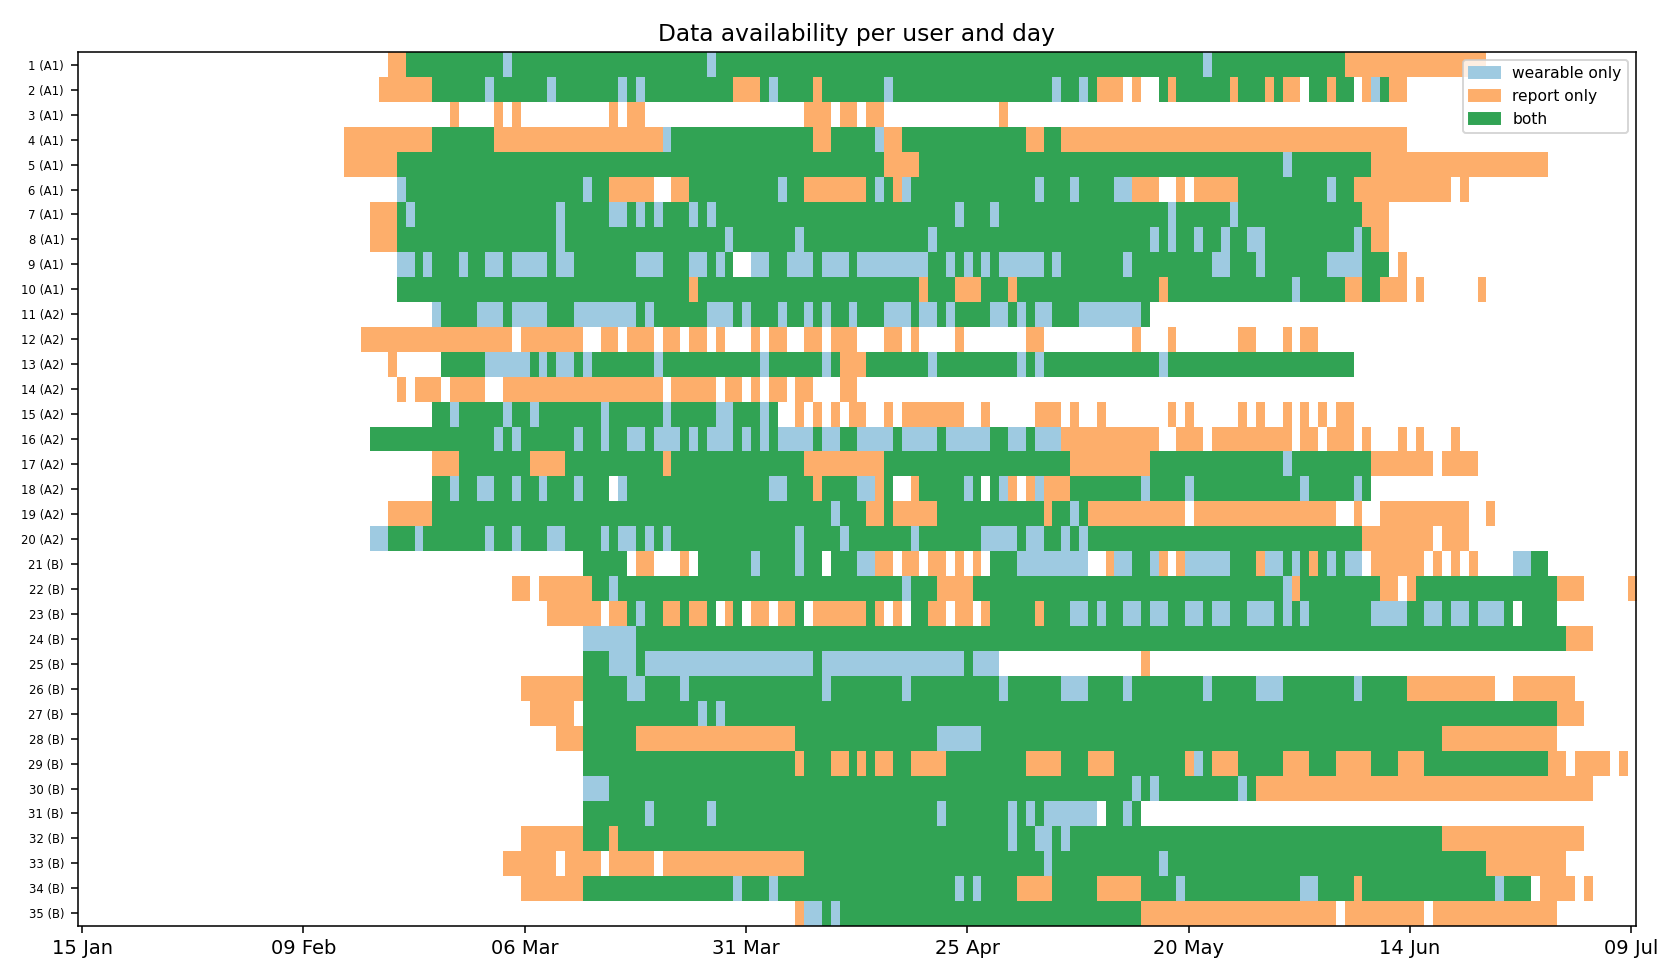

02_report_distributions.png


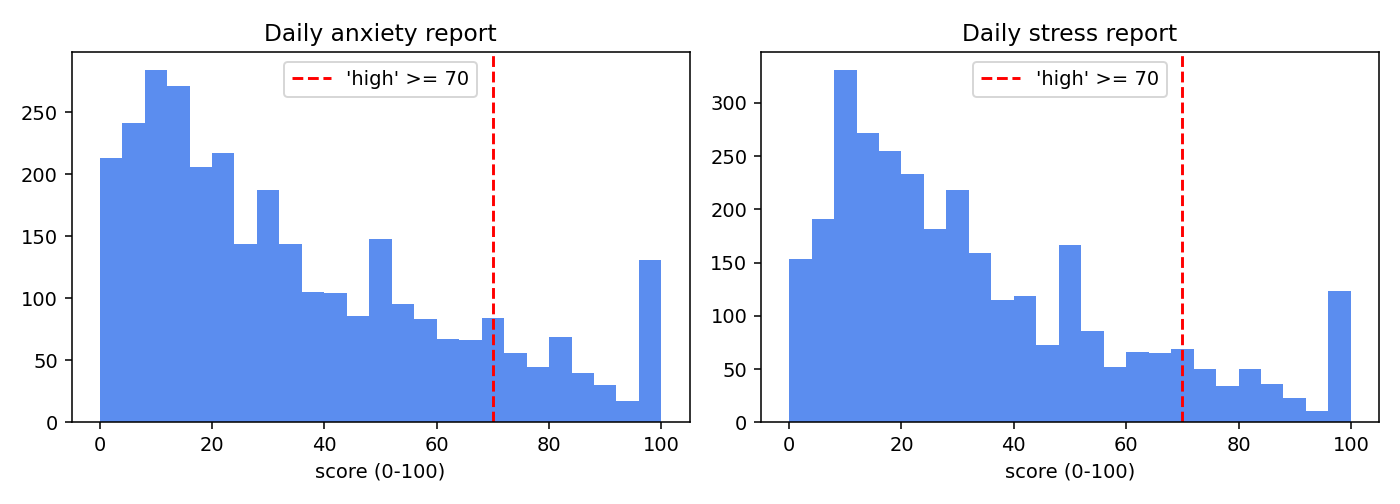

03_example_users.png


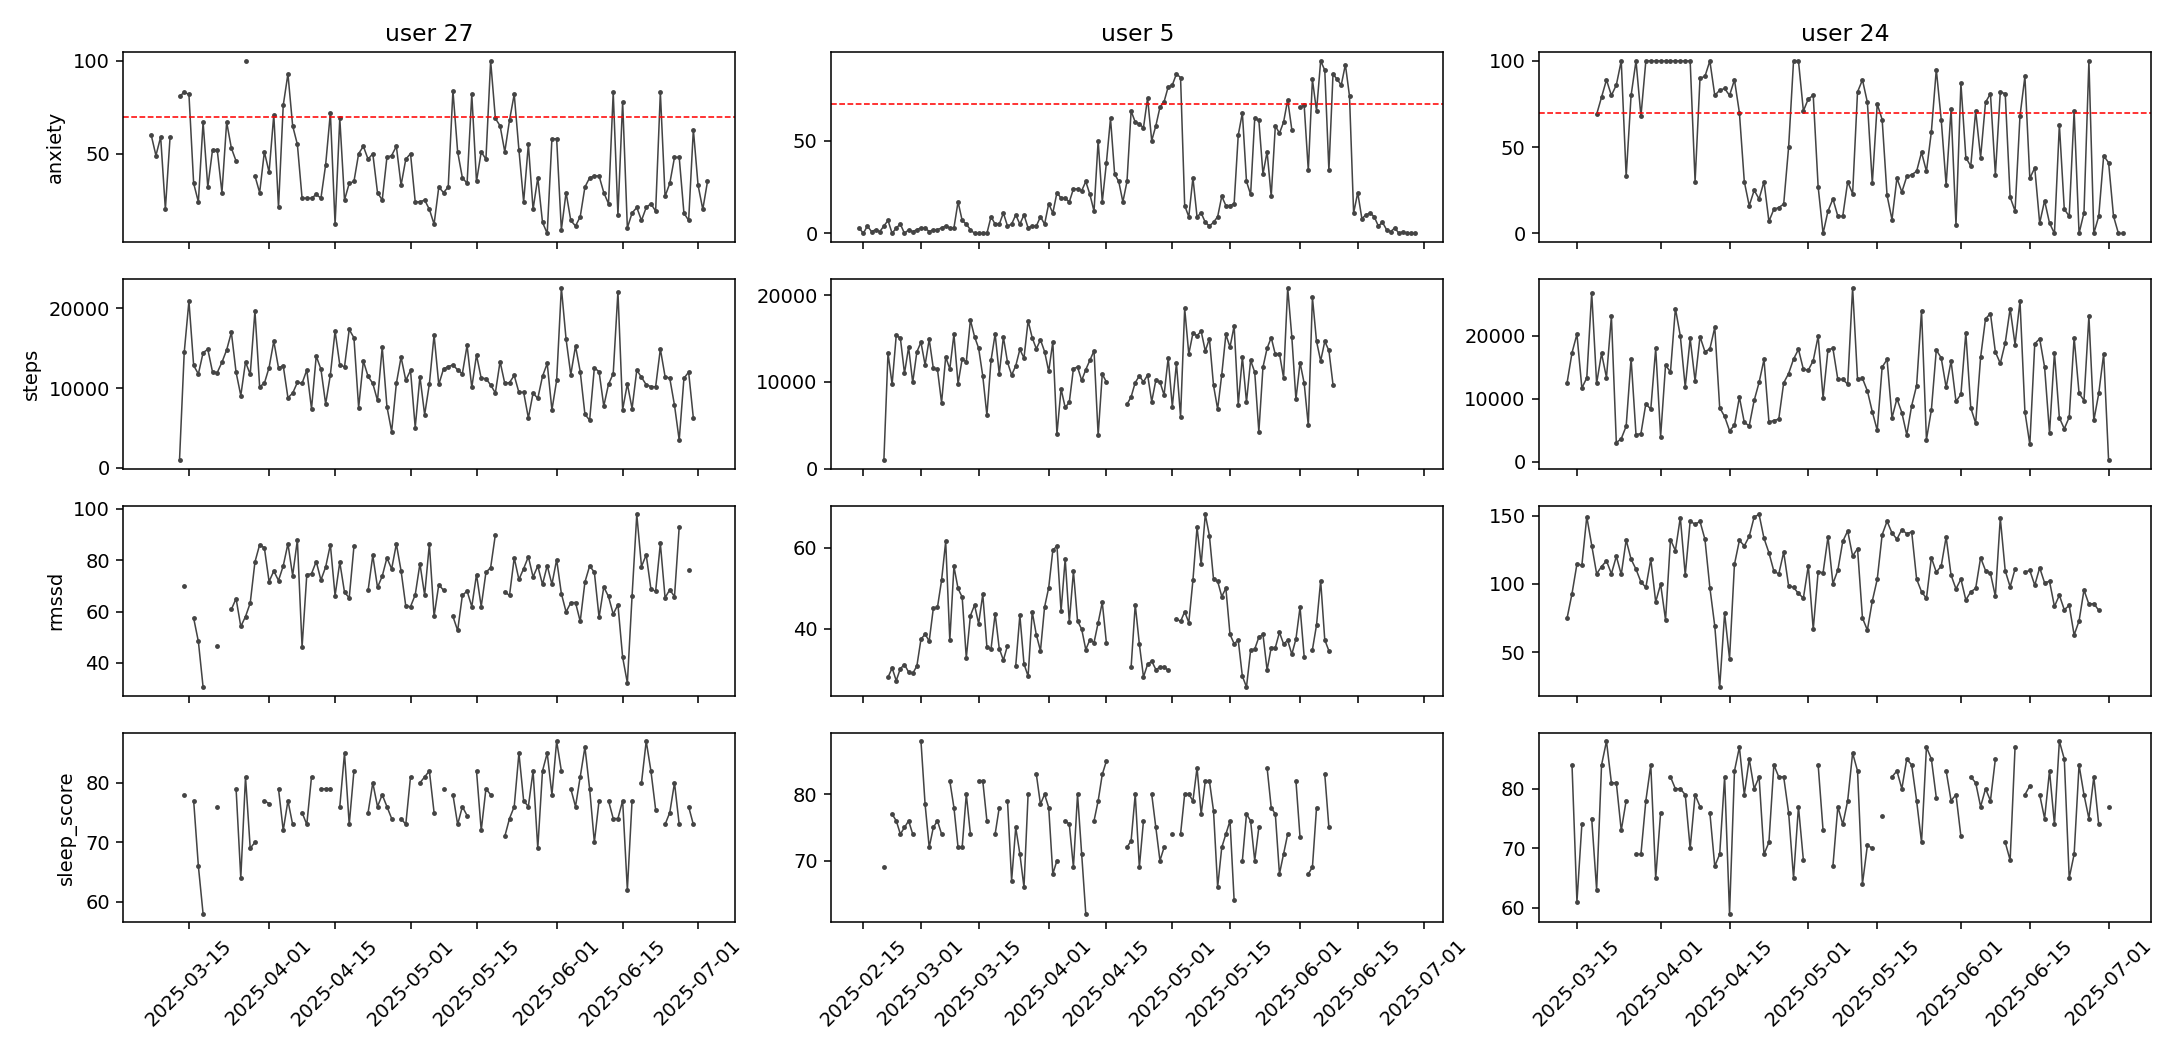

04_label_balance.png


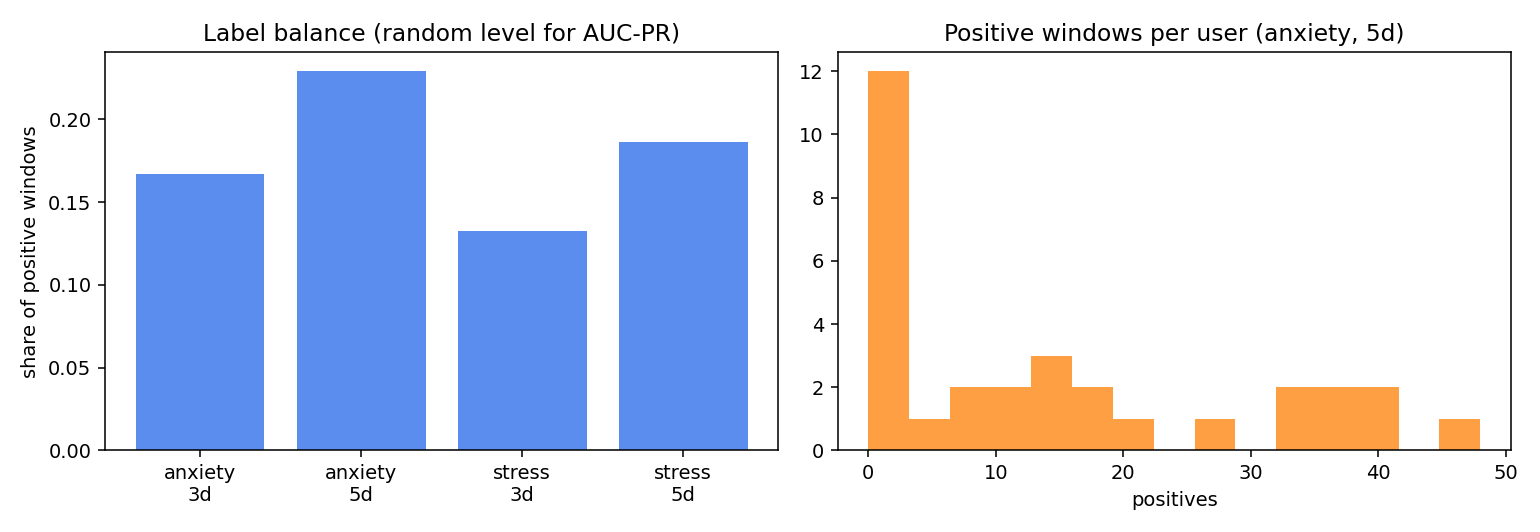

In [ ]:
# CELL 16 - look at the figures
from IPython.display import Image, display
import glob
for f in sorted(glob.glob(WORKDIR + '/results/eda/*.png')):
    print(os.path.basename(f)); display(Image(f))

## Training (checkpoints, early stopping, best model, resume)

In [ ]:
# CELL 17 - SMOKE TEST: 3 epochs on 1 fold, only to check that everything runs
!python -m src.train --folds 0 --run_name smoke --set train.epochs=3

[train] run 'smoke' on cuda | workdir /content/drive/MyDrive/HCI_PROJECT/kanode
[data] loaded cached windows samples_d0798183dd.pt
[fold 0 seed 0] start: train 1402 / val 291 / test 425 windows
[fold 0] ep   1  train 0.0790  val 0.0871  valAP 0.2347  valAUROC 0.469  *best*
[fold 0] ep   2  train 0.0627  val 0.0830  valAP 0.2233  valAUROC 0.457  (no gain 1/15)
[fold 0] ep   3  train 0.0598  val 0.0830  valAP 0.2169  valAUROC 0.441  (no gain 2/15)
[fold 0] DONE  best epoch 1  val AP 0.2347  test AP 0.3437  test AUROC 0.529


In [ ]:
# CELL 18 - FULL TRAINING. Safe to stop (Runtime > Interrupt) and run again: it resumes where it stopped.
# Saved after EVERY epoch: runs/<run>/fold<k>_seed<s>/last.pt ; best model on validation users: best.pt
!python -m src.train

[train] run 'kanode_w14_h3-5' on cuda | workdir /content/drive/MyDrive/HCI_PROJECT/kanode
[data] loaded cached windows samples_d0798183dd.pt
[fold 0 seed 0] start: train 1402 / val 291 / test 425 windows
[fold 0] ep   1  train 0.0790  val 0.0871  valAP 0.2347  valAUROC 0.469  *best*
[fold 0] ep   2  train 0.0627  val 0.0830  valAP 0.2233  valAUROC 0.457  (no gain 1/15)
[fold 0] ep   3  train 0.0598  val 0.0830  valAP 0.2169  valAUROC 0.441  (no gain 2/15)
[fold 0] ep   4  train 0.0570  val 0.0848  valAP 0.2159  valAUROC 0.441  (no gain 3/15)
[fold 0] ep   5  train 0.0554  val 0.0890  valAP 0.2138  valAUROC 0.443  (no gain 4/15)
[fold 0] ep   6  train 0.0546  val 0.0827  valAP 0.2237  valAUROC 0.447  (no gain 5/15)
[fold 0] ep   7  train 0.0532  val 0.0795  valAP 0.2440  valAUROC 0.469  *best*
[fold 0] ep   8  train 0.0520  val 0.0905  valAP 0.2146  valAUROC 0.424  (no gain 1/15)
[fold 0] ep   9  train 0.0511  val 0.0874  valAP 0.2263  valAUROC 0.425  (no gain 2/15)
[fold 0] ep  10  tra

,epoch,train_loss,val_loss,val_macro_ap,val_macro_auroc,lr,seconds
16,17,0.039413,0.091384,0.240372,0.478086,0.00050,0.9
17,18,0.036575,0.132118,0.230623,0.460917,0.00050,0.9
18,19,0.033693,0.117495,0.225398,0.463178,0.00050,0.9
19,20,0.032181,0.138842,0.218412,0.456210,0.00050,0.9
20,21,0.029661,0.139654,0.221910,0.481330,0.00050,0.9
21,22,0.030973,0.124448,0.214932,0.460264,0.00050,0.9
22,23,0.030067,0.155064,0.225692,0.482535,0.00025,0.9
23,24,0.027556,0.141637,0.221058,0.474854,0.00025,0.9
24,25,0.026463,0.150657,0.221460,0.480033,0.00025,0.9
25,26,0.025777,0.158873,0.219854,0.479946,0.00025,0.9


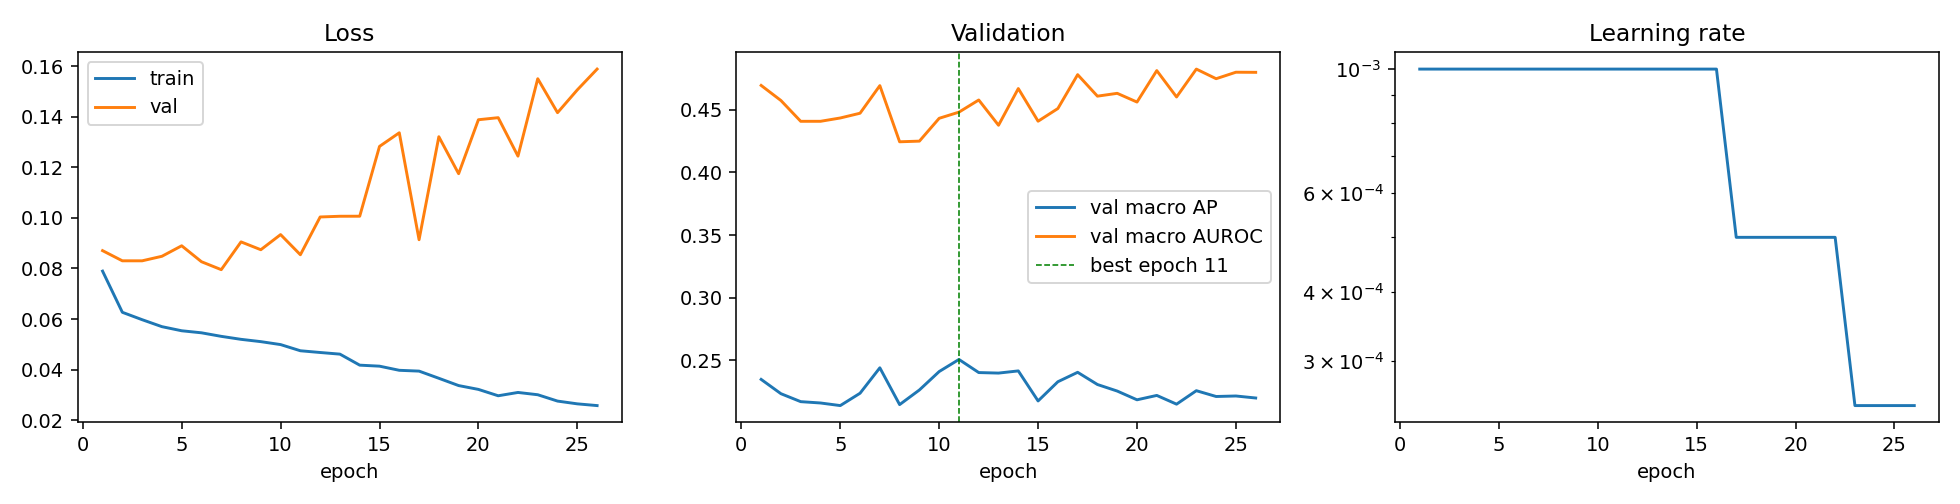

In [ ]:
# CELL 18b (optional) - watch the training curves of a fold while it trains / after a restart
import pandas as pd
h = pd.read_csv(WORKDIR + '/runs/kanode_w14_h3-5/fold0_seed0/history.csv'); display(h.tail(10))
display(Image(WORKDIR + '/runs/kanode_w14_h3-5/fold0_seed0/training_curves.png'))

## Evaluation

In [ ]:
# CELL 19 - metrics vs baselines, lead time, conformal coverage per course / university
!python -m src.evaluate

[data] loaded cached windows samples_d0798183dd.pt
[split] re-using saved splits (/content/drive/MyDrive/HCI_PROJECT/kanode/runs/kanode_w14_h3-5/splits.json)
[data] loaded cached daily table (4853 rows)
[eval] finished folds: [0, 1, 2, 3, 4]

=== Test metrics (mean over folds; AP should be compared with 'prevalence') ===
                      method    task  horizon  auroc_mean  auroc_std  ap_mean  ap_std  prevalence    n
          GBM + past reports anxiety        3       0.660      0.094    0.381   0.143       0.173 1914
          GBM + past reports anxiety        5       0.633      0.052    0.420   0.120       0.236 1916
          GBM + past reports  stress        3       0.617      0.094    0.212   0.103       0.139 1977
          GBM + past reports  stress        5       0.613      0.056    0.285   0.144       0.194 1977
           GBM wearable-only anxiety        3       0.534      0.062    0.202   0.086       0.173 1914
           GBM wearable-only anxiety        5       0.520  

conformal_by_course.png


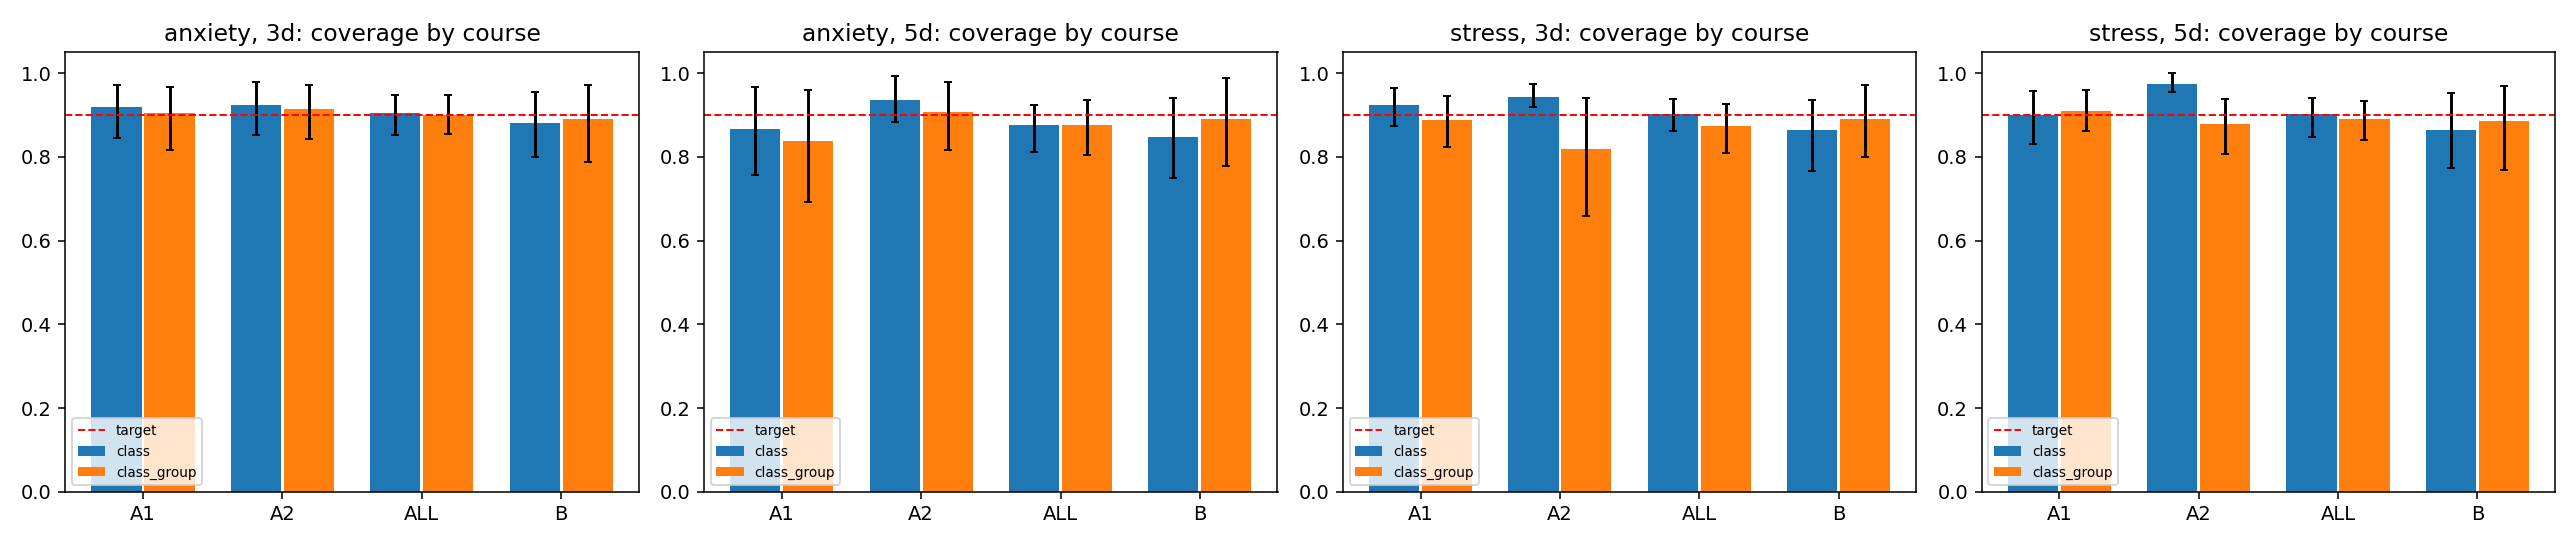

conformal_by_course_setsizes.png


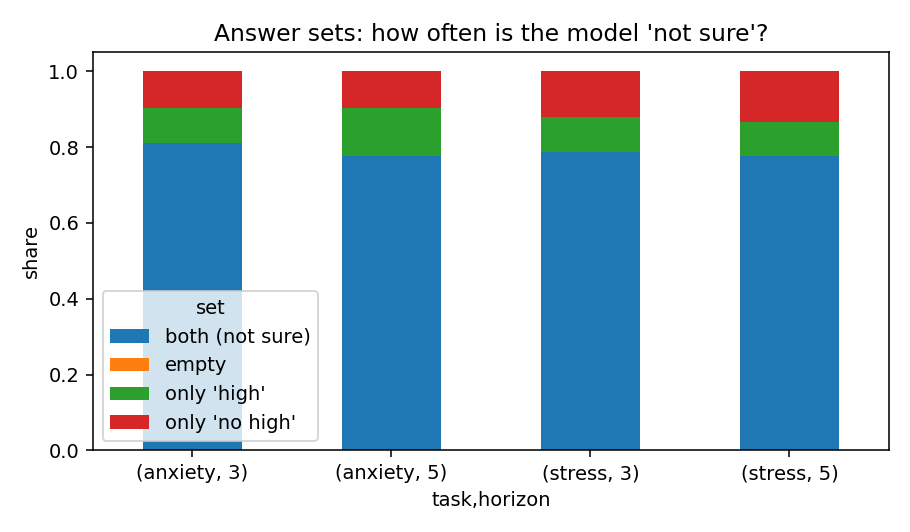

conformal_by_university.png


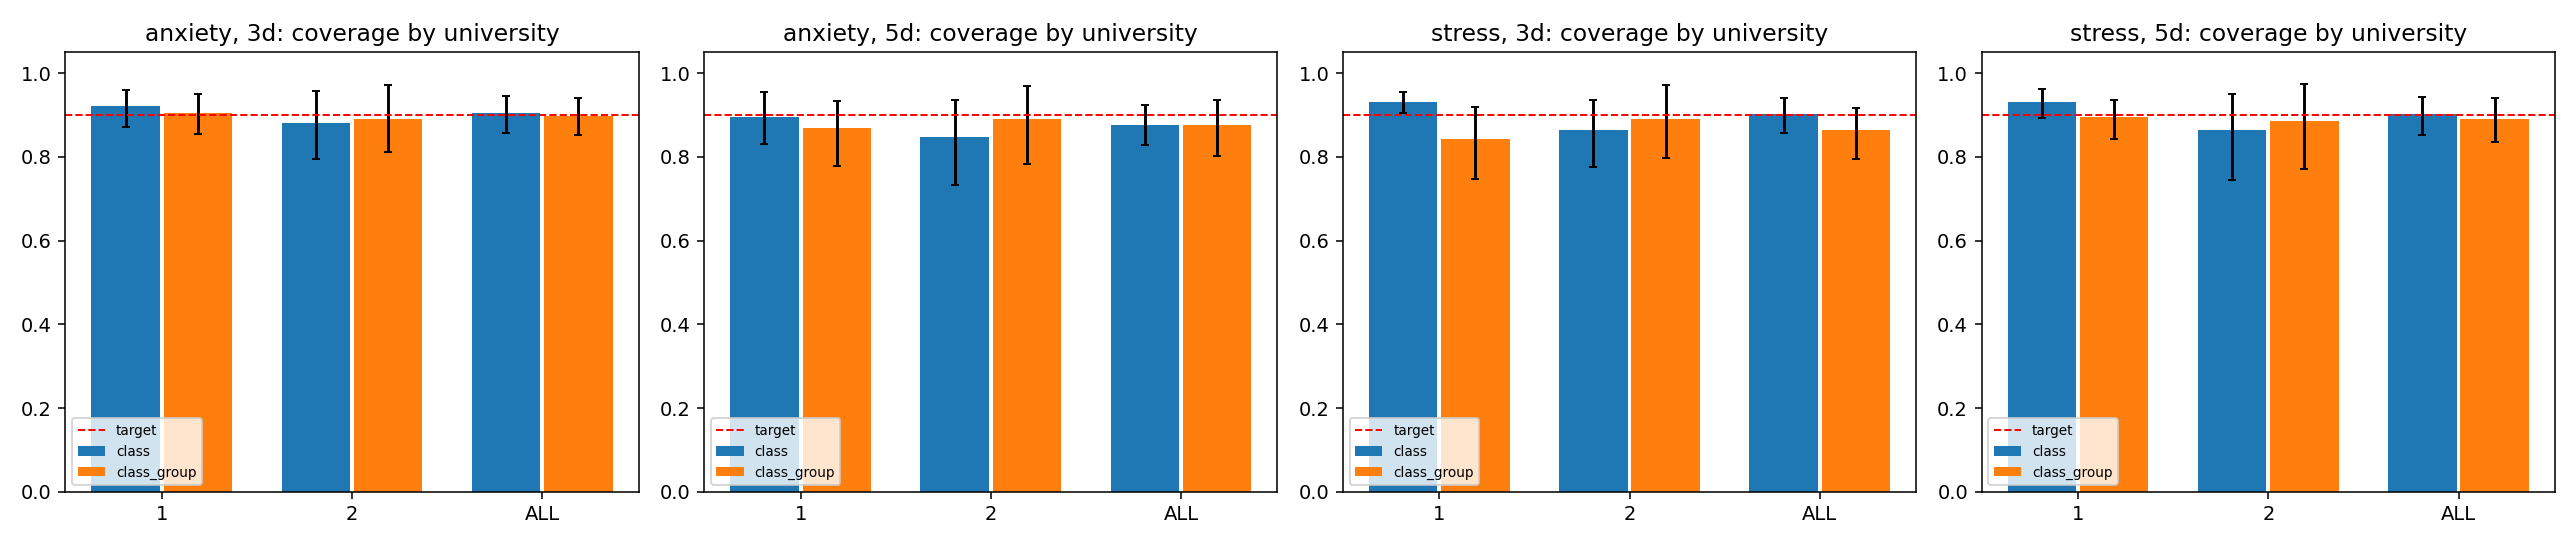

conformal_by_university_setsizes.png


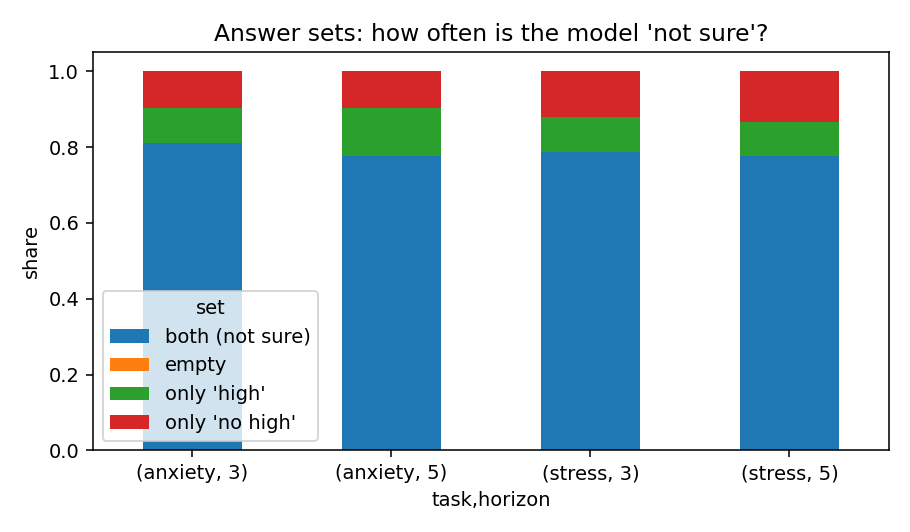

curves_pr_roc.png


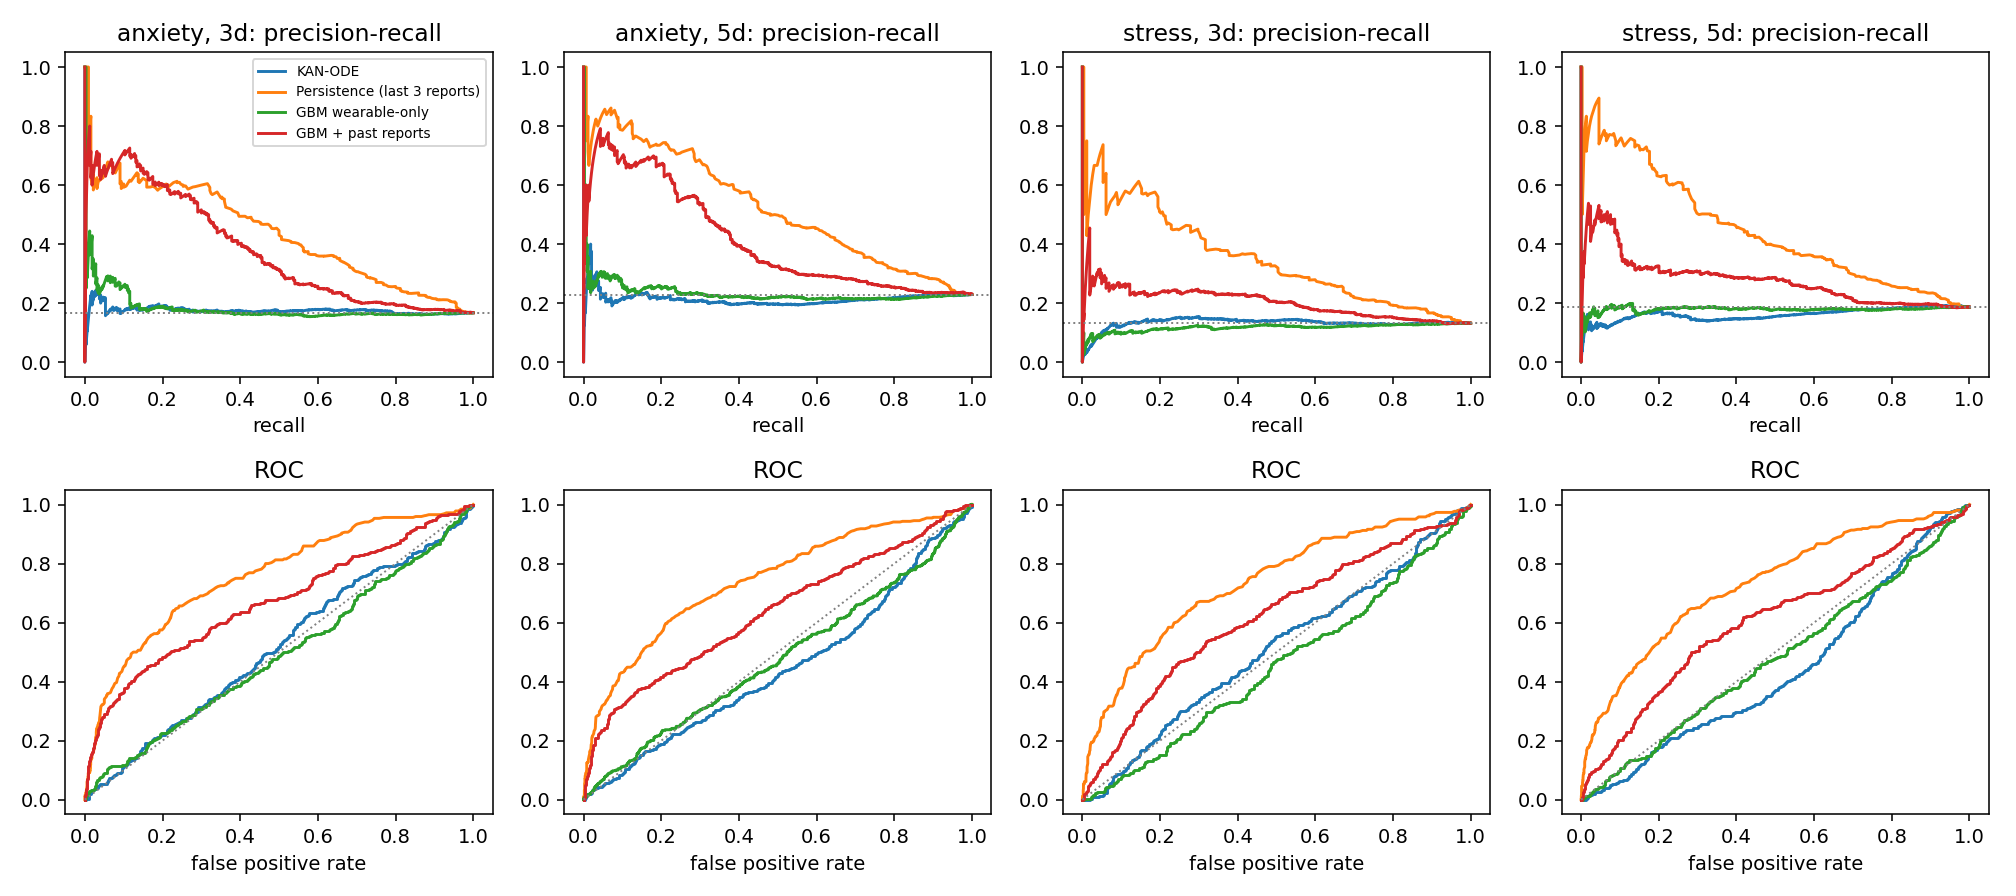

lead_time.png


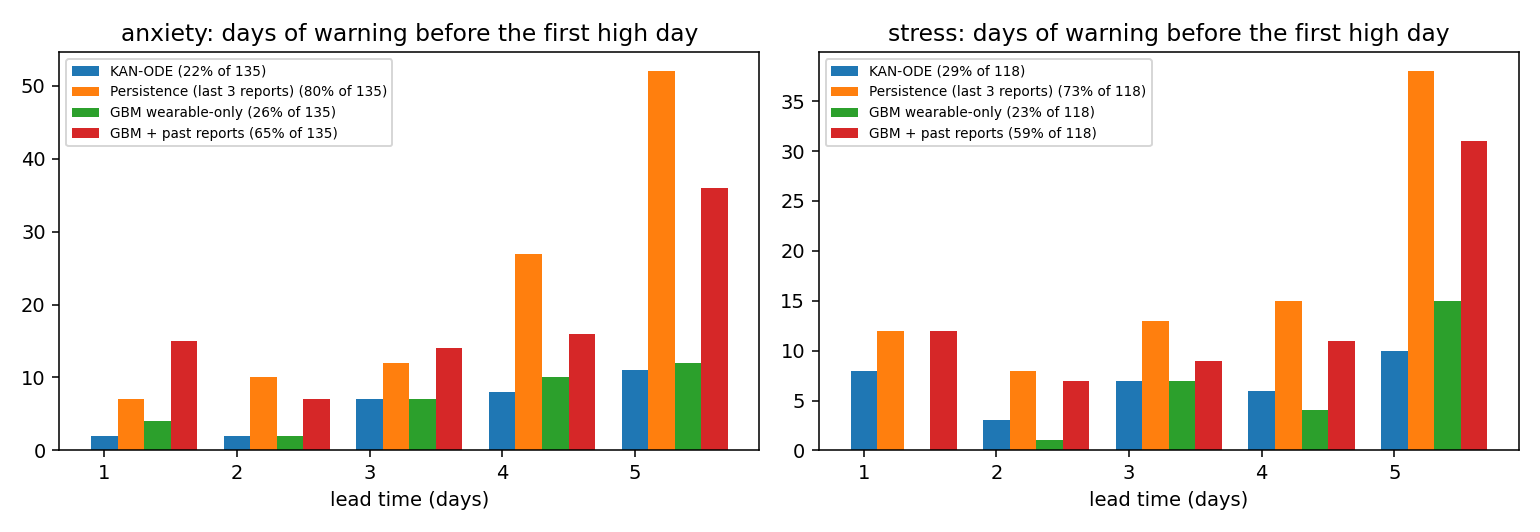

reliability.png


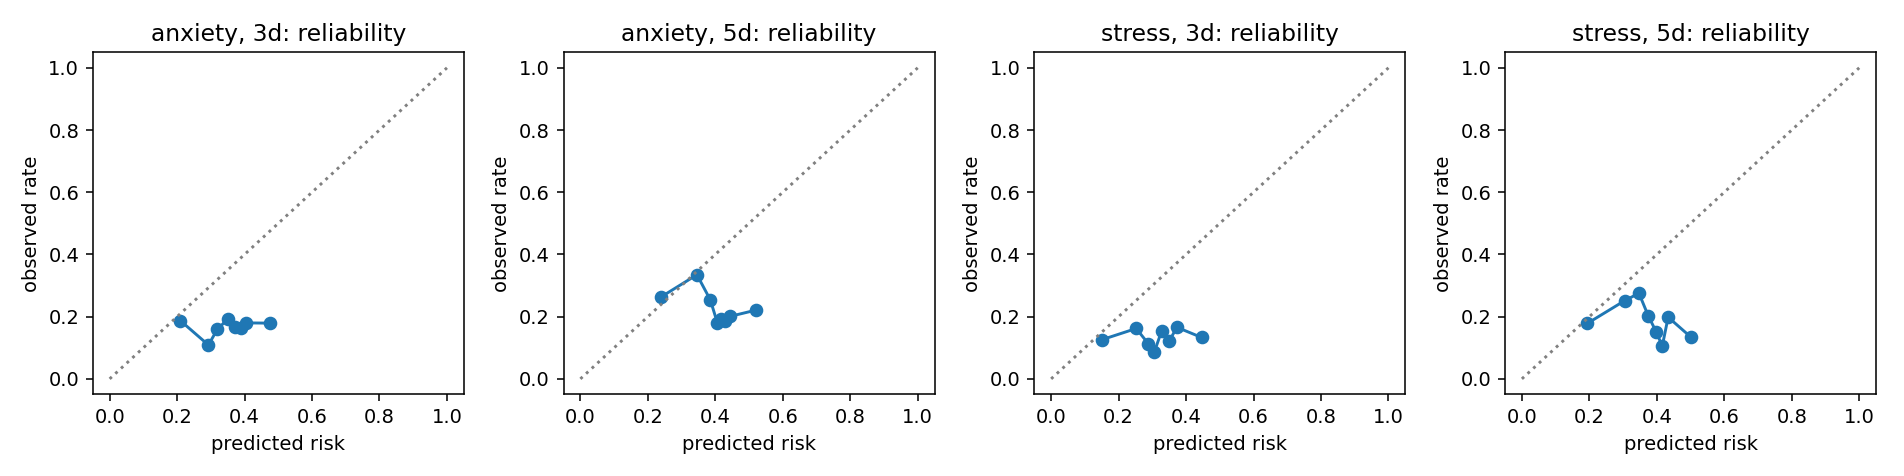

state_pca.png


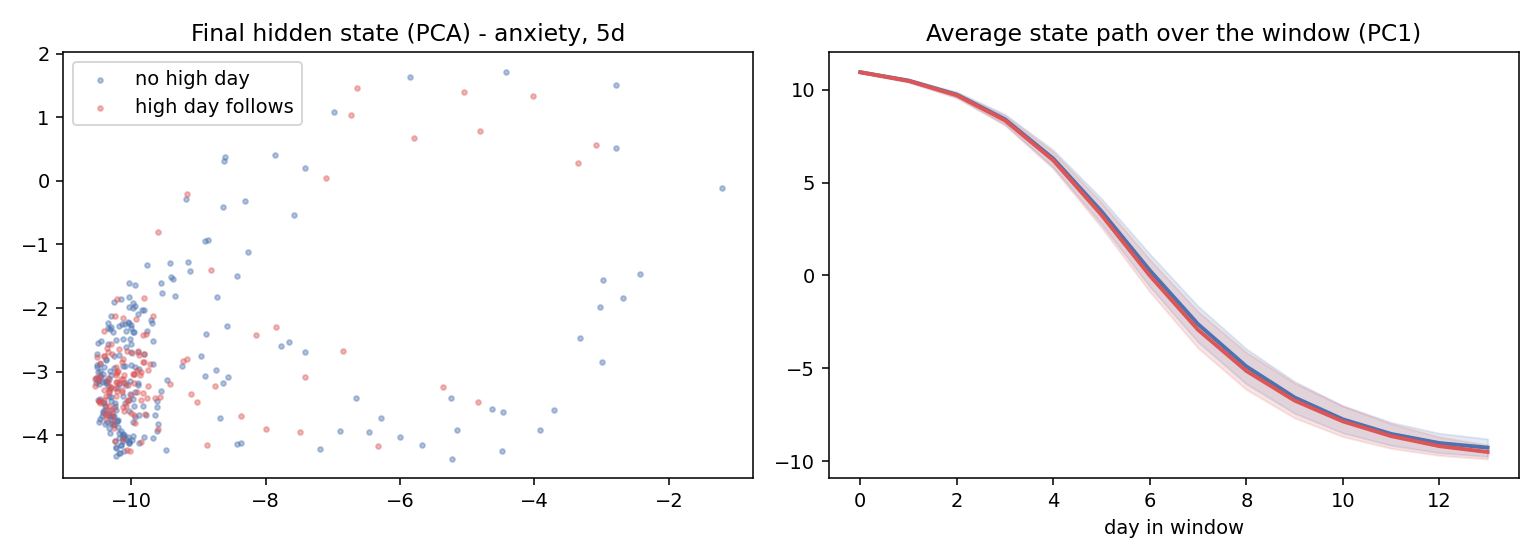

input_importance.png


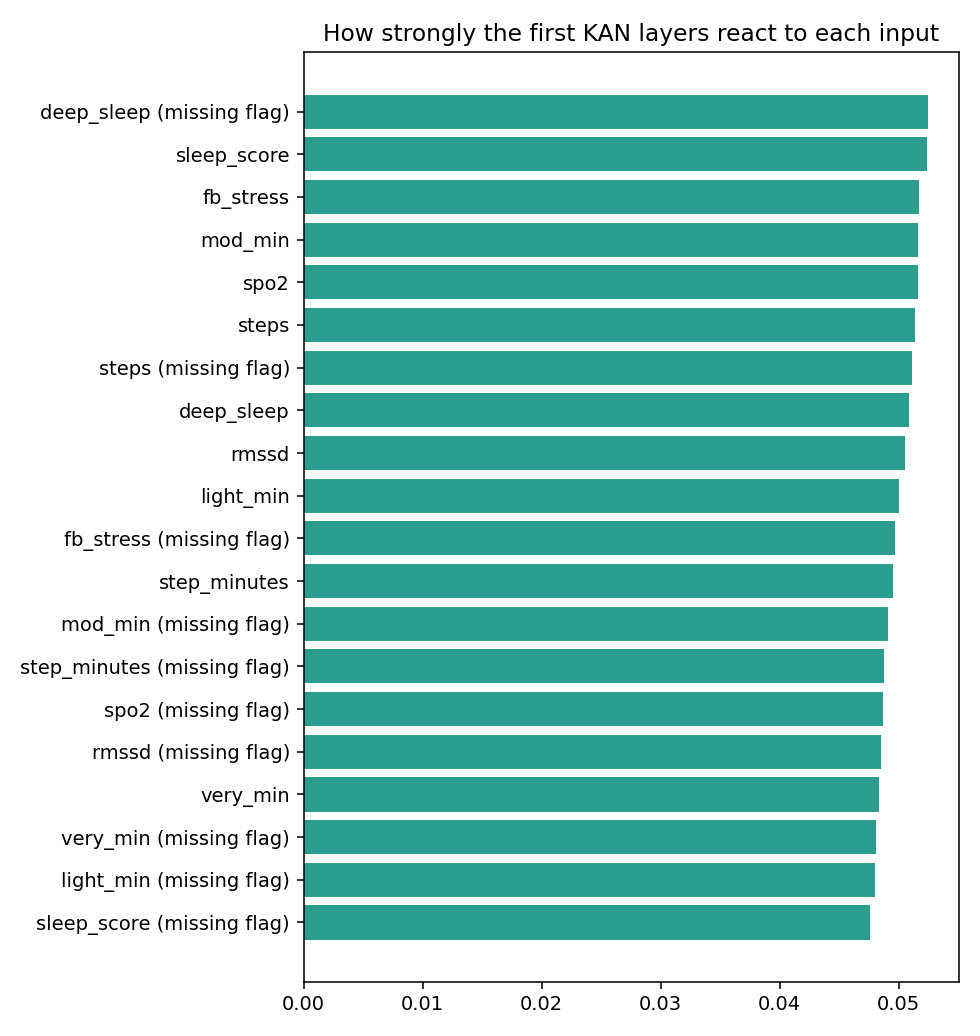

dynamics_f.png


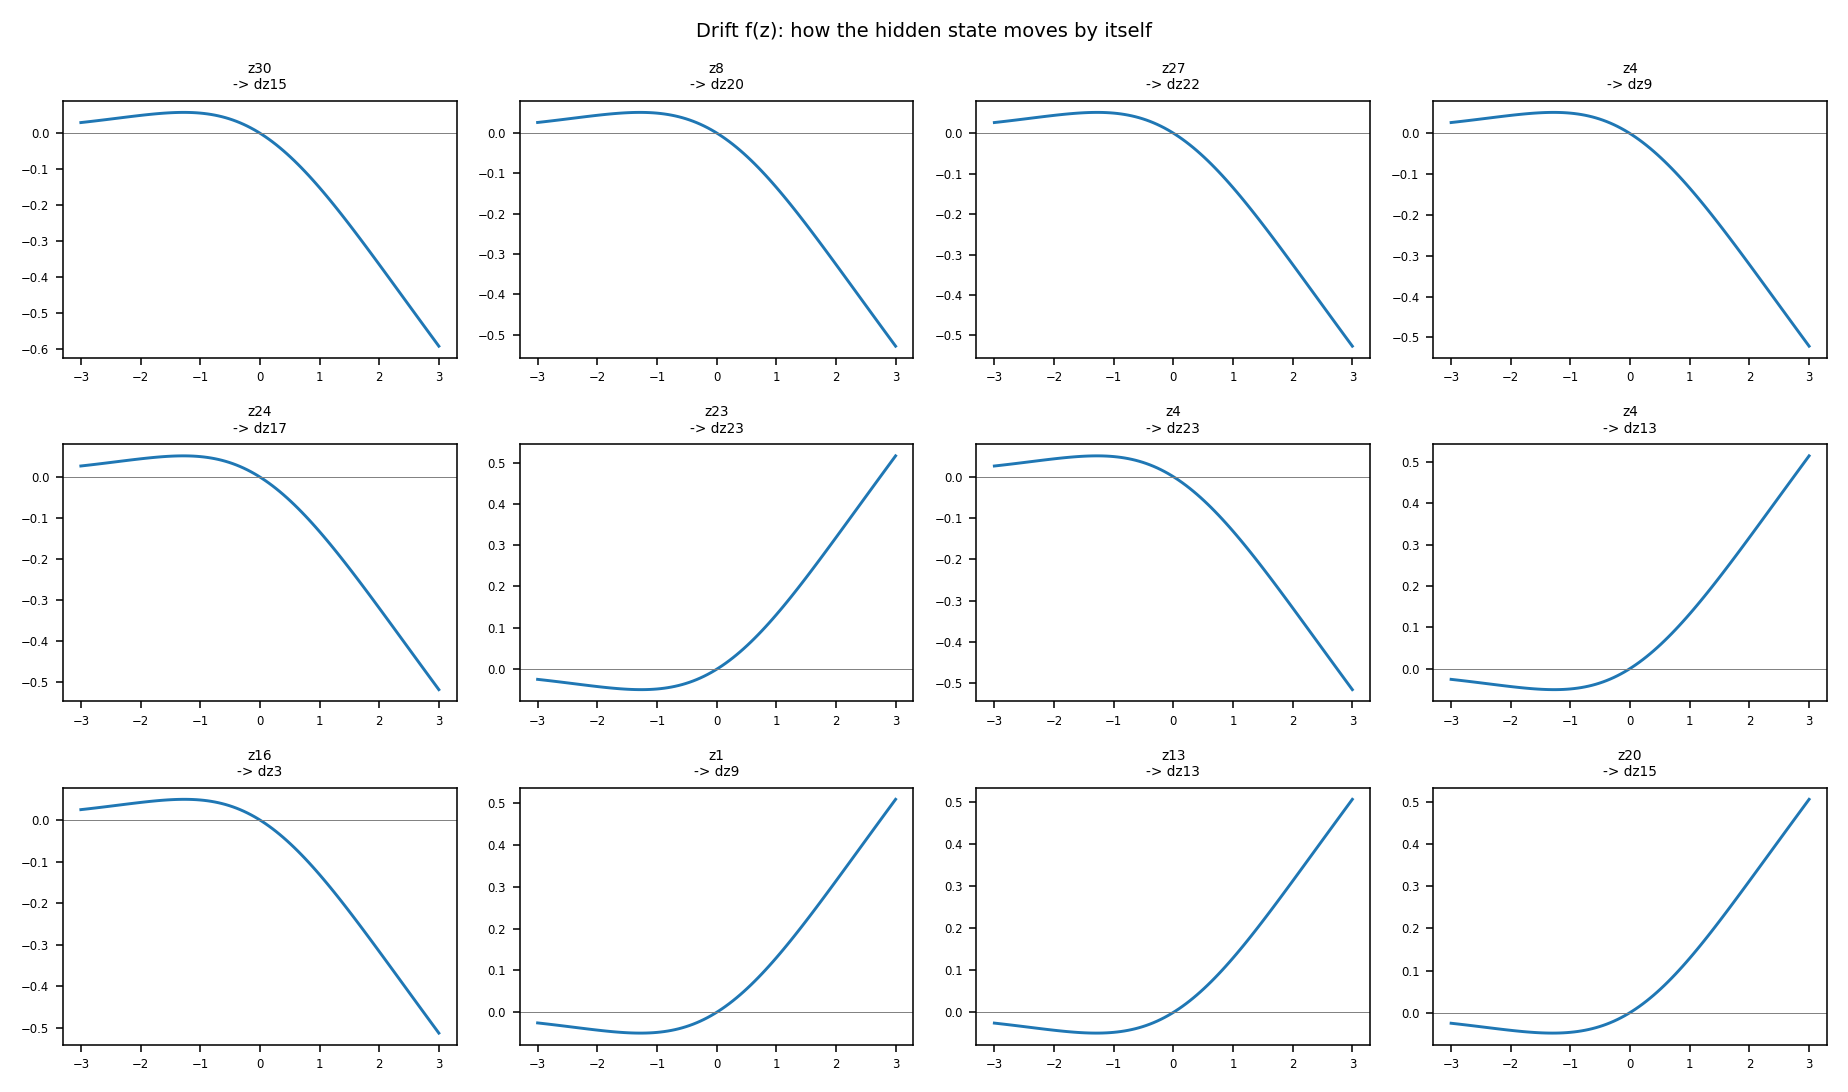

In [ ]:
# CELL 20 - show every result figure (ROC/PR, reliability, lead time, conformal, learned KAN curves, hidden state)
res = WORKDIR + '/results/kanode_w14_h3-5/figures'
for f in sorted(glob.glob(res + '/*.png')):
    print(os.path.basename(f)); display(Image(f))
run0 = WORKDIR + '/runs/kanode_w14_h3-5/fold0_seed0'
for f in [run0 + '/state_pca.png', run0 + '/splines/input_importance.png', run0 + '/splines/dynamics_f.png']:
    if os.path.exists(f): print(os.path.basename(f)); display(Image(f))

## Ablations: does the hidden state help? does KAN help?

In [ ]:
# CELL 21 - each command gets its own run folder, so nothing is overwritten (each takes a while; resumable)
!python -m src.train --set model.state_model=pooling
!python -m src.train --set model.state_model=gru
!python -m src.train --set model.layer_type=mlp
!python -m src.evaluate --set model.state_model=pooling --skip_gbm
!python -m src.evaluate --set model.state_model=gru --skip_gbm
!python -m src.evaluate --set model.layer_type=mlp --skip_gbm

[train] run 'kanode_w14_h3-5__state_model-pooling' on cuda | workdir /content/drive/MyDrive/HCI_PROJECT/kanode
[data] loaded cached windows samples_d0798183dd.pt
[fold 0 seed 0] start: train 1402 / val 291 / test 425 windows
[fold 0] ep   1  train 0.0872  val 0.0749  valAP 0.1962  valAUROC 0.434  *best*
[fold 0] ep   2  train 0.0626  val 0.0808  valAP 0.1964  valAUROC 0.430  (no gain 1/15)
[fold 0] ep   3  train 0.0587  val 0.0748  valAP 0.1976  valAUROC 0.422  *best*
[fold 0] ep   4  train 0.0570  val 0.0766  valAP 0.1947  valAUROC 0.422  (no gain 1/15)
[fold 0] ep   5  train 0.0562  val 0.0757  valAP 0.1937  valAUROC 0.423  (no gain 2/15)
[fold 0] ep   6  train 0.0555  val 0.0762  valAP 0.1963  valAUROC 0.429  (no gain 3/15)
[fold 0] ep   7  train 0.0547  val 0.0785  valAP 0.1998  valAUROC 0.431  *best*
[fold 0] ep   8  train 0.0537  val 0.0763  valAP 0.2137  valAUROC 0.438  *best*
[fold 0] ep   9  train 0.0527  val 0.0823  valAP 0.2102  valAUROC 0.434  (no gain 1/15)
[fold 0] ep  10

run         GBM + past reports  GBM wearable-only  Persistence (last 3 reports)  kanode_w14_h3-5  kanode_w14_h3-5__layer_type-mlp  kanode_w14_h3-5__state_model-gru  kanode_w14_h3-5__state_model-pooling
key                                                                                                                                                                                                      
anxiety 3d               0.381              0.202                         0.400            0.190                            0.188                             0.203                                 0.196
anxiety 5d               0.420              0.259                         0.504            0.243                            0.248                             0.279                                 0.260
stress 3d                0.212              0.142                         0.318            0.180                            0.149                             0.141                             

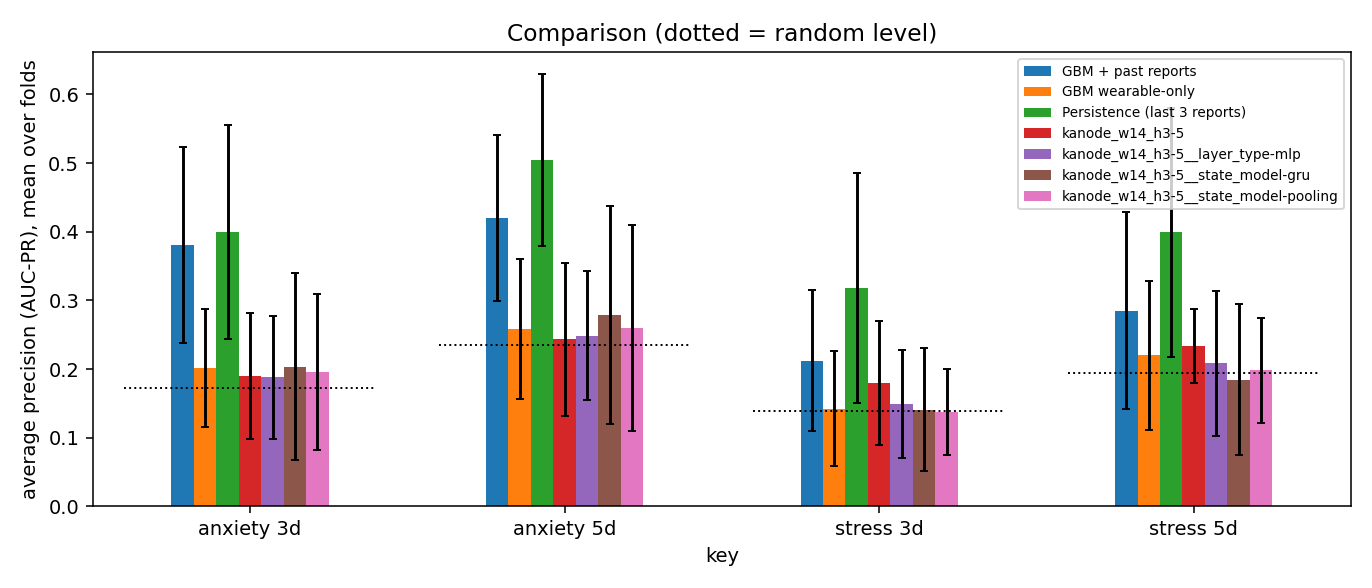

In [ ]:
# CELL 22 - one figure comparing all runs (dotted line = random level)
!python -m src.compare_runs --runs kanode_w14_h3-5 kanode_w14_h3-5__state_model-pooling kanode_w14_h3-5__state_model-gru kanode_w14_h3-5__layer_type-mlp --name ablation
display(Image(WORKDIR + '/results/ablation_comparison/comparison_ap.png'))